# Assignment 2: Generalization in Deep Networks

**Course:** AAI 6640: Applied Deep Learning  
**Module:** Week 5 (5.6)  
**Author:** Muhammad Obaidullah Abdul Salam  
**Dataset:** Fashion-MNIST (Keras)  
**Task:** 10-class image classification with a fixed dense network  

## Overview

**Objective:** measure how weight initialization, L2 regularization, dropout, and early stopping change the learning behavior and generalization of one fixed dense network, 784 → 128 ReLU → 128 ReLU → 10 softmax, trained on Fashion-MNIST.

**Approach:** prepare → baseline → change one technique at a time → select on validation → evaluate once on test → compare.

### Experimental design

Each run changes exactly one setting relative to its reference, so any difference between the two is attributable to that setting.

| Run | Hidden-layer initializer | L2 on hidden kernels | Dropout after each hidden layer | Reference | What changes |
|---|---|---|---|---|---|
| Baseline | Glorot uniform (Keras default) | — | — | — | — |
| He init | He normal | — | — | Baseline | initializer |
| He + L2 0.001 | He normal | 0.001 | — | He init | L2 strength |
| He + L2 0.01 | He normal | 0.01 | — | He init | L2 strength |
| He + dropout 0.2 | He normal | — | 0.2 | He init | dropout rate |
| He + dropout 0.4 | He normal | — | 0.4 | He init | dropout rate |

**Held constant in every run:** the 50,000 / 10,000 / 10,000 split, the architecture, ReLU hidden activations, the softmax output layer (Keras default initializer, no regularization), Adam at its default learning rate, sparse categorical cross-entropy, accuracy, `BATCH_SIZE`, `EPOCHS`, and the random seed, reset before every model is built.

**Early stopping.** Every run trains for the full `EPOCHS` and keeps the weights from its epoch of highest validation accuracy, so all curves cover the same horizon and show what happens after the stopping point. A patience-based `EarlyStopping` rule could halt these flat, noisy validation curves before their highest peak, and its outcome would depend on the patience chosen. The criterion is validation accuracy, the brief's metric. Validation loss turns much earlier, at epoch 8 in both unregularized runs (Steps 2 and 3). Step 7 compares the retained weights with the epoch-50 weights and with a loss-based rule, which would stop sooner.

**Reporting rule:** unless stated otherwise, every metric is taken at the epoch of best validation accuracy (epochs counted from 1).

**Results at a glance.** Every choice used validation results only; the test set was scored once, in Step 6.

| Run | Best val acc | Best epoch | Train acc (Keras) | Train acc, dropout off | Gap (Keras train − val) |
|---|---|---|---|---|---|
| Baseline (Glorot) | 0.8987 | 21 | 0.9383 | 0.9321 | 0.0396 |
| He init | 0.8968 | 31 | 0.9540 | 0.9389 | 0.0572 |
| He + L2 0.001 | 0.8920 | 48 | 0.9120 | 0.9098 | 0.0200 |
| He + L2 0.01 | 0.8667 | 45 | 0.8628 | 0.8638 | −0.0039 |
| **He + dropout 0.2 (final)** | **0.9031** | 41 | 0.9234 | 0.9351 | 0.0203 |
| He + dropout 0.4 | 0.8977 | 50 | 0.8983 | 0.9230 | 0.0006 |

| Final model: He + dropout 0.2, epoch-41 weights | Value |
|---|---|
| Test accuracy | 0.8873 |
| Test loss (cross-entropy) | 0.3445 |

**Findings.** He initialization changed mainly the first epochs. L2 and dropout both narrowed the train–validation gap, but only dropout 0.2 did so without giving up training fit. It is also the only change that raised validation accuracy by more than half a point (see Step 6 on margins).

## Setup

All imports, constants, and display settings.

**Reproducibility.**

| Item | Value |
|---|---|
| Libraries | Python 3.12.11, TensorFlow 2.21.0, Keras 3.15.1 (TensorFlow backend), scikit-learn 1.9.1, NumPy 2.5.3, pandas 3.0.6, Matplotlib 3.11.2 (printed by the cell below) |
| Hardware | CPU only (Apple M1 Pro); no GPU |
| Split seed | `SEED = 42` fixes the stratified train/validation split (Step 1) |
| Training seed | `keras.utils.set_random_seed(SEED)`, called by `train` and by Step 3's `activation_scale` right before each model is built |
| Determinism | `tf.config.experimental.enable_op_determinism()` (below); same versions and hardware reproduce every training history exactly |
| Data | Fashion-MNIST via `fashion_mnist.load_data()`: about 30 MB, downloaded on the first run (needs internet), then read from `~/.keras/datasets` |
| Preprocessing | Step 1 only: flatten, scale, split |
| Runtime | About 4 min, fresh kernel, top to bottom; nearly all of it is the six training runs of Steps 2–5, 34–39 s each (printed by `train`) |

In [37]:
import os
import platform

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # before TensorFlow loads; hides C++ notices

import time
from dataclasses import dataclass, replace

import keras
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from keras import layers, regularizers
from matplotlib.lines import Line2D
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets import fashion_mnist

SEED = 42
EPOCHS = 50
BATCH_SIZE = 128
N_VAL = 10_000
HIDDEN_UNITS = 128
CLASS_NAMES = (
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
)
N_CLASSES = len(CLASS_NAMES)

tf.config.experimental.enable_op_determinism()

set_matplotlib_formats("retina")
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "font.size": 11,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.3,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 4)

print(
    f"Python {platform.python_version()} | TensorFlow {tf.__version__} | "
    f"Keras {keras.__version__} | scikit-learn {sklearn.__version__} | "
    f"NumPy {np.__version__} | pandas {pd.__version__} | Matplotlib {matplotlib.__version__}"
)
print(f"Devices: {', '.join(device.device_type for device in tf.config.list_physical_devices())}")

Python 3.12.11 | TensorFlow 2.21.0 | Keras 3.15.1 | scikit-learn 1.9.1 | NumPy 2.5.3 | pandas 3.0.6 | Matplotlib 3.11.2
Devices: CPU


## Step 1 — Data preparation

Fashion-MNIST: 70,000 grayscale 28 × 28 images of clothing in 10 balanced classes, 60,000 for training and 10,000 for testing (Xiao et al., 2017).

In [38]:
(X_train_full, y_train_full), (X_test_raw, y_test_raw) = fashion_mnist.load_data()

for name, images, labels in (
    ("Training (full)", X_train_full, y_train_full),
    ("Test", X_test_raw, y_test_raw),
):
    print(
        f"{name:16} images {images.shape} {images.dtype}, "
        f"pixels {images.min()}–{images.max()} | "
        f"labels {labels.shape} {labels.dtype}, classes {labels.min()}–{labels.max()}"
    )

Training (full)  images (60000, 28, 28) uint8, pixels 0–255 | labels (60000,) uint8, classes 0–9
Test             images (10000, 28, 28) uint8, pixels 0–255 | labels (10000,) uint8, classes 0–9


Each image is flattened to 784 values and divided by 255. Validation is drawn from the 60,000 training images by a stratified split (`random_state=SEED`), so its class mix matches the training set. The original 10,000 test images stay apart until Step 6. Labels stay as integers 0–9, which is what sparse categorical cross-entropy expects.

In [39]:
@dataclass(frozen=True)
class Split:
    """One partition: flattened images `X` (rows × 784, float32 in [0, 1]) and integer labels `y`."""

    X: np.ndarray
    y: np.ndarray


@dataclass(frozen=True)
class Splits:
    """The training, validation, and test partitions."""

    train: Split
    val: Split
    test: Split


def flatten_and_scale(images: np.ndarray) -> np.ndarray:
    """Flatten 28 × 28 images to 784 values and map pixels from 0–255 to [0, 1]."""
    return images.reshape(len(images), -1).astype(np.float32) / 255.0


def prepare_splits(
    X_full: np.ndarray, y_full: np.ndarray, 
    X_test: np.ndarray, y_test: np.ndarray
) -> Splits:
    """Hold out N_VAL stratified validation images from the training set; keep the test set as given."""
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_full, y_full, test_size=N_VAL, stratify=y_full, random_state=SEED
    )
    return Splits(
        Split(flatten_and_scale(X_tr), y_tr.astype(np.int32)),
        Split(flatten_and_scale(X_val), y_val.astype(np.int32)),
        Split(flatten_and_scale(X_test), y_test.astype(np.int32)),
    )


data = prepare_splits(X_train_full, y_train_full, X_test_raw, y_test_raw)

In [40]:
def split_profile(part: Split) -> dict[str, object]:
    """Size, pixel range, label type, and class balance of one split."""
    counts = np.bincount(part.y, minlength=N_CLASSES)
    return {
        "Rows": len(part.y),
        "Features": part.X.shape[1],
        "Min pixel": part.X.min(),
        "Max pixel": part.X.max(),
        "Mean pixel": part.X.mean(),
        "Label dtype": str(part.y.dtype),
        "Smallest class": counts.min(),
        "Largest class": counts.max(),
    }


parts = {"Training": data.train, "Validation": data.val, "Test": data.test}
pd.DataFrame.from_dict({name: split_profile(part) for name, part in parts.items()}, orient="index")

,Rows,Features,Min pixel,Max pixel,Mean pixel,Label dtype,Smallest class,Largest class
Training,50000,784,0.0,1.0,0.2863,int32,5000,5000
Validation,10000,784,0.0,1.0,0.2849,int32,1000,1000
Test,10000,784,0.0,1.0,0.2868,int32,1000,1000


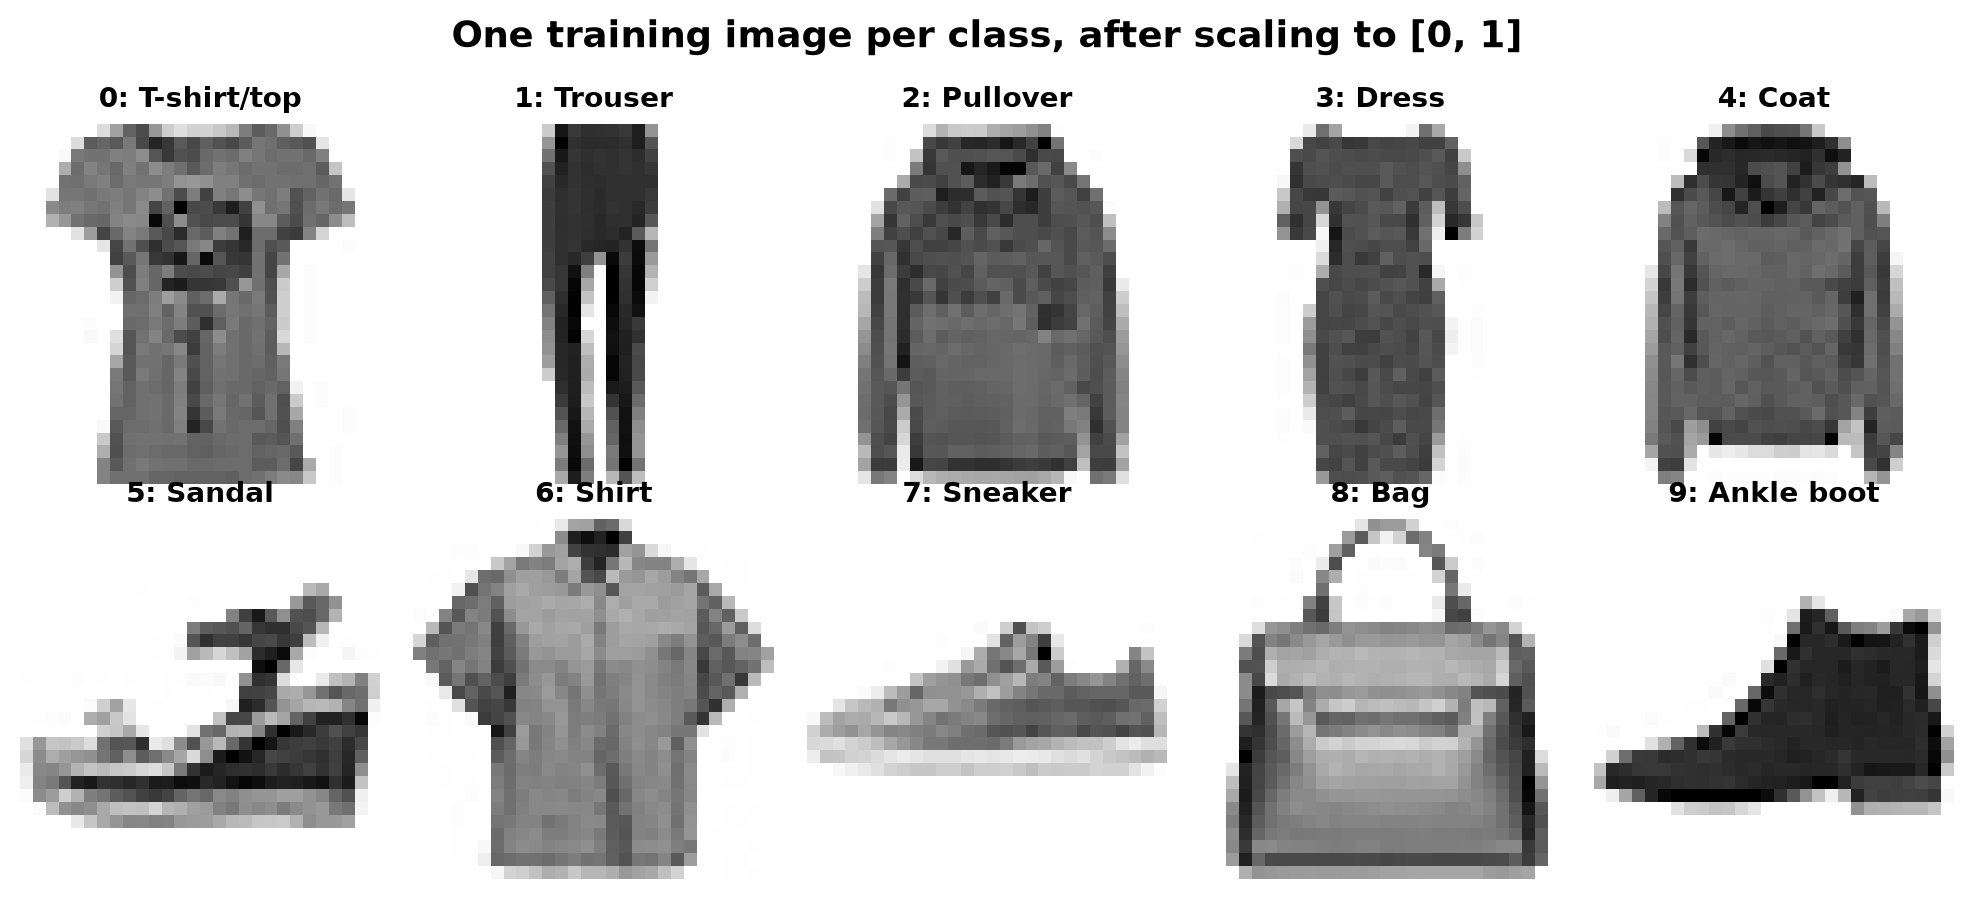

In [41]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.6))
for label, ax in enumerate(axes.flat):
    image = data.train.X[np.flatnonzero(data.train.y == label)[0]].reshape(28, 28)
    ax.imshow(image, cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"{label}: {CLASS_NAMES[label]}", fontsize=10)
    ax.axis("off")
fig.suptitle("One training image per class, after scaling to [0, 1]", fontweight="bold")
fig.tight_layout()
plt.show()

**Reading the check.** The split gives 50,000 training, 10,000 validation, and 10,000 test images of 784 features each, with exactly 5,000, 1,000, and 1,000 images per class. Pixels span 0.0 to 1.0 in every split, with nearly identical means (0.2863, 0.2849, 0.2868), and labels are `int32`. Several classes, such as T-shirt/top, Pullover, Coat, and Shirt, share an upper-body silhouette that the network must separate from raw pixels (images above). The test split's profile is descriptive only and informed no decision.

**Why normalization is appropriate.** Every feature is a pixel intensity in the same unit (0–255), so scaling is about magnitude, not about balancing features of different units. Glorot and He initialization set weight variances so that pre-activations start at roughly the scale of the inputs, which assumes inputs of order 1. Raw inputs up to 255 would make the first layer's pre-activations about 255 times larger, push the initial softmax toward saturation, and start training with a large loss and large gradients. Dividing by 255 maps every pixel into [0, 1] and keeps relative intensities unchanged. The divisor is fixed in advance rather than estimated from data, so this step cannot leak validation or test information.

**Why the test set is not used for model selection.** Every choice in this notebook (L2 strength, dropout rate, retained epoch) picks the best-scoring candidate on some dataset, and so also picks up that dataset's noise. With hundreds of checkpoints across 6 runs × `EPOCHS` epochs, the highest validation accuracy among them overestimates how the chosen model performs on new data. Validation absorbs that selection bias. The test set stays untouched until one model is fixed, so a single evaluation on it gives an unbiased estimate of performance on unseen images. If the test set informed any choice, that estimate would be biased too, and no unseen data would remain to measure generalization.

## Models, training, and reporting

Shared code for every experiment.

| Item | Value |
|---|---|
| `Config` | Per-run settings: initializer, L2, dropout. Six runs, matching the Overview design table |
| `build_model` | 784 → 128 ReLU → 128 ReLU → 10 softmax |
| Technique scope | Hidden layers only. Output layer: Keras default initializer, no regularization |
| `train` | Reset seed → score validation before training → train → restore best weights |
| Training set | 50,000 images; the only data fit |
| Validation set | 10,000 images; scored every epoch |
| Test set | Unused until Step 6 |
| Optimizer | Adam, Keras defaults (learning rate 0.001, β₁ 0.9, β₂ 0.999, ε 10⁻⁷); fixed by the brief |
| Loss | Sparse categorical cross-entropy |
| Metric | Accuracy |
| Epochs | 50 (`EPOCHS`), no patience-based stopping. Brief allows 40 or 50; 50 shows more post-peak overfitting |
| Batch size | 128 (`BATCH_SIZE`); 391 updates per epoch |
| Shuffling | Every epoch (Keras default) |
| Bias init | Zeros (Keras default) |
| Weights kept | Best validation-accuracy epoch (`BestWeights`) |

In [42]:
@dataclass(frozen=True)
class Config:
    """The settings that vary between experiments; everything else is fixed."""

    name: str
    initializer: str = "glorot_uniform"  # the Keras default for Dense kernels
    l2: float = 0.0  # L2 factor on the hidden-layer kernels
    dropout: float = 0.0  # rate of the Dropout layer after each hidden layer


def build_model(config: Config) -> keras.Sequential:
    """784 → 128 ReLU → 128 ReLU → 10 softmax, with `config` applied to the hidden layers only."""
    regularizer = regularizers.l2(config.l2) if config.l2 else None
    stack = [keras.Input(shape=(784,), name="pixels")]
    for i in (1, 2):
        stack.append(
            layers.Dense(
                HIDDEN_UNITS,
                activation="relu",
                kernel_initializer=config.initializer,
                kernel_regularizer=regularizer,
                name=f"hidden_{i}",
            )
        )
        if config.dropout:
            stack.append(layers.Dropout(config.dropout, name=f"dropout_{i}"))
    stack.append(layers.Dense(N_CLASSES, activation="softmax", name="output"))
    model = keras.Sequential(stack)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def describe(config: Config) -> str:
    """One-line description of a configuration."""
    settings = [
        f"hidden init {config.initializer}",
        f"L2 {config.l2:g}" if config.l2 else "no L2",
        f"dropout {config.dropout:g}" if config.dropout else "no dropout",
    ]
    return "784 → 128 ReLU → 128 ReLU → 10 softmax; " + ", ".join(settings)


BASELINE = Config("Baseline")
HE = Config("He init", initializer="he_normal")
L2_CONFIGS = (
    replace(HE, name="He + L2 0.001", l2=0.001),
    replace(HE, name="He + L2 0.01", l2=0.01),
)
DROPOUT_CONFIGS = (
    replace(HE, name="He + dropout 0.2", dropout=0.2),
    replace(HE, name="He + dropout 0.4", dropout=0.4),
)
ALL_CONFIGS = (BASELINE, HE, *L2_CONFIGS, *DROPOUT_CONFIGS)
COLORS = {config.name: f"C{i}" for i, config in enumerate(ALL_CONFIGS)}

pd.DataFrame(
    {
        config.name: {
            "Hidden-layer initializer": config.initializer,
            "L2 (hidden kernels)": config.l2 or "—",
            "Dropout (after each hidden layer)": config.dropout or "—",
        }
        for config in ALL_CONFIGS
    }
).T

,Hidden-layer initializer,L2 (hidden kernels),Dropout (after each hidden layer)
Baseline,glorot_uniform,—,—
He init,he_normal,—,—
He + L2 0.001,he_normal,0.001,—
He + L2 0.01,he_normal,0.01,—
He + dropout 0.2,he_normal,—,0.2
He + dropout 0.4,he_normal,—,0.4


In [43]:
build_model(BASELINE).summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,282 (462.04 KB)

 Trainable params: 118,282 (462.04 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
class BestWeights(keras.callbacks.Callback):
    """Keep a copy of the weights from the epoch with the highest validation accuracy."""

    def __init__(self):
        super().__init__()
        self.best_accuracy, self.epoch, self.weights = -np.inf, None, None

    def on_epoch_end(self, epoch, logs=None):
        if logs["val_accuracy"] > self.best_accuracy:
            self.best_accuracy, self.epoch = logs["val_accuracy"], epoch + 1
            self.weights = self.model.get_weights()


@dataclass(frozen=True)
class Run:
    """A trained experiment: the model holds the weights of its best validation epoch."""

    config: Config
    model: keras.Sequential
    history: pd.DataFrame  # one row per epoch, indexed 1..EPOCHS
    best_epoch: int
    initial: dict[str, float]  # validation loss and accuracy before the first update
    seconds: float


def train(config: Config, data: Splits) -> Run:
    """Train one configuration for EPOCHS epochs and restore its best-validation-accuracy weights."""
    keras.utils.set_random_seed(SEED)  # every run starts from the same random state
    model = build_model(config)
    val_loss, val_accuracy = model.evaluate(
        data.val.X, data.val.y, batch_size=BATCH_SIZE, verbose=0
    )
    best = BestWeights()
    start = time.perf_counter()
    fit = model.fit(
        data.train.X,
        data.train.y,
        validation_data=(data.val.X, data.val.y),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[best],
        verbose=0,
    )
    seconds = time.perf_counter() - start
    model.set_weights(best.weights)
    history = pd.DataFrame(fit.history, index=pd.RangeIndex(1, EPOCHS + 1, name="epoch"))
    print(
        f"{config.name}: best validation accuracy {best.best_accuracy:.4f} "
        f"at epoch {best.epoch}/{EPOCHS} ({seconds:.0f} s)"
    )
    return Run(
        config,
        model,
        history,
        best.epoch,
        {"val_loss": val_loss, "val_accuracy": val_accuracy},
        seconds,
    )


def best_val_accuracy(run: Run) -> float:
    """Highest validation accuracy over all epochs."""
    return float(run.history["val_accuracy"].max())


def best_of(runs: list[Run]) -> Run:
    """The run with the highest validation accuracy; ties go to the earlier run in `runs`."""
    return max(runs, key=best_val_accuracy)

**Two views of training accuracy.** Keras's per-epoch training accuracy is a running average over the epoch's mini-batches, taken while the weights are still changing and, in the dropout runs, with dropout active. Validation accuracy is measured once at the end of the epoch with dropout off. `summarize` reports Keras's number under the reporting rule. It also adds `Train acc, dropout off`: the restored best weights scored on all 50,000 training images in inference mode, the same conditions as validation.

**Loss without the penalty.** With L2, Keras adds $\lambda \sum w^2$ over the hidden kernels to the reported loss, so a regularized model's loss is not comparable with an unregularized one's. `Train CE` and `Val CE` are cross-entropy alone, computed from the predicted probabilities and comparable across all runs. `Hidden ‖W‖` is the Euclidean norm of both hidden kernels together; it shows how much L2 actually shrinks the weights.

**Where validation loss turns.** `Lowest val loss`, `Epoch of lowest val loss`, and `Val loss at epoch 50` come from Keras's per-epoch validation loss (penalty included for the L2 runs). Validation loss can turn upward before validation accuracy stops improving, so these columns show overfitting that the accuracy curves can hide.

In [45]:
def cross_entropy(probs: np.ndarray, labels: np.ndarray) -> float:
    """Mean sparse categorical cross-entropy, clipped like Keras, with no regularization term."""
    picked = np.clip(probs[np.arange(len(labels)), labels], 1e-7, 1.0)
    return float(-np.log(picked).mean())


def inference_metrics(model: keras.Model, part: Split) -> tuple[float, float]:
    """Cross-entropy and accuracy on one split with dropout off."""
    probs = model.predict(part.X, batch_size=1024, verbose=0)
    return cross_entropy(probs, part.y), float(np.mean(probs.argmax(axis=1) == part.y))


def hidden_weight_norm(model: keras.Model) -> float:
    """Euclidean norm of both hidden-layer kernels taken together."""
    kernels = (keras.ops.convert_to_numpy(model.get_layer(f"hidden_{i}").kernel) for i in (1, 2))
    return float(np.sqrt(sum(np.sum(kernel**2) for kernel in kernels)))


def summarize(run: Run, data: Splits) -> dict[str, float]:
    """Metrics under the reporting rule: at the epoch of best validation accuracy."""
    at_best, last = run.history.loc[run.best_epoch], run.history.iloc[-1]
    train_ce, train_accuracy = inference_metrics(run.model, data.train)
    val_ce, _ = inference_metrics(run.model, data.val)
    return {
        "Best epoch": run.best_epoch,
        "Train acc": at_best["accuracy"],
        "Val acc": at_best["val_accuracy"],
        "Gap (train − val)": at_best["accuracy"] - at_best["val_accuracy"],
        "Train acc, dropout off": train_accuracy,
        "Train CE": train_ce,
        "Val CE": val_ce,
        "Hidden ‖W‖": hidden_weight_norm(run.model),
        f"Gap at epoch {EPOCHS}": last["accuracy"] - last["val_accuracy"],
        "Lowest val loss": run.history["val_loss"].min(),
        "Epoch of lowest val loss": int(run.history["val_loss"].idxmin()),
        f"Val loss at epoch {EPOCHS}": last["val_loss"],
    }


def summary_table(runs: list[Run], data: Splits) -> pd.DataFrame:
    """One row per run under the reporting rule."""
    return pd.DataFrame.from_dict(
        {run.config.name: summarize(run, data) for run in runs}, orient="index"
    )

In [46]:
def _legend_handles(runs: list[Run]) -> list[Line2D]:
    """Color per run, plus line styles for training, validation, and the best epoch."""
    return [Line2D([], [], color=COLORS[run.config.name], label=run.config.name) for run in runs] + [
        Line2D([], [], color="0.3", ls="--", label="Training"),
        Line2D([], [], color="0.3", label="Validation"),
        Line2D([], [], color="0.3", marker="o", ls="", label="Best validation accuracy"),
    ]


def plot_curves(runs: list[Run], title: str) -> None:
    """Overlay accuracy and loss for several runs: training dashed, validation solid."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for run in runs:
        color, history, best = COLORS[run.config.name], run.history, run.best_epoch
        for ax, metric in zip(axes, ("accuracy", "loss")):
            ax.plot(history.index, history[metric], ls="--", color=color, alpha=0.8)
            ax.plot(history.index, history[f"val_{metric}"], color=color)
            ax.plot(best, history.loc[best, f"val_{metric}"], "o", color=color, ms=6)
    axes[0].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[1].set(title="Loss (as reported by Keras)", xlabel="Epoch", ylabel="Loss")
    handles = _legend_handles(runs)
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.07))
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    plt.show()


def plot_grid(runs: list[Run], title: str) -> None:
    """One row per run with accuracy and loss; y-ranges shared by column so rows compare directly.

    The loss range is set from epoch 2 on, so one run's large epoch-1 training loss cannot flatten
    every other curve; a panel whose epoch-1 value falls off the scale says so in its title.
    """
    histories = [run.history for run in runs]
    accuracy = [h[["accuracy", "val_accuracy"]] for h in histories]
    loss_top = 1.05 * max(h[["loss", "val_loss"]].iloc[1:].max().max() for h in histories)
    limits = {
        "accuracy": (min(a.min().min() for a in accuracy) - 0.01, max(a.max().max() for a in accuracy) + 0.01),
        "loss": (0.0, loss_top),
    }
    fig, axes = plt.subplots(len(runs), 2, figsize=(13, 3.2 * len(runs)), sharex=True, squeeze=False)
    for row, run in zip(axes, runs):
        color, history, best = COLORS[run.config.name], run.history, run.best_epoch
        for ax, metric in zip(row, ("accuracy", "loss")):
            ax.plot(history.index, history[metric], ls="--", color=color, label="Training")
            ax.plot(history.index, history[f"val_{metric}"], color=color, label="Validation")
            ax.axvline(best, color="0.5", lw=0.8, ls=":", label=f"Best val acc (epoch {best})")
            off_scale = history[[metric, f"val_{metric}"]].max().max() > limits[metric][1]
            note = " (epoch 1 off scale)" if off_scale else ""
            ax.set(title=f"{run.config.name}: {metric}{note}", ylabel=metric.capitalize(), ylim=limits[metric])
        row[0].legend(loc="lower right")
    for ax in axes[-1]:
        ax.set_xlabel("Epoch")
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    plt.show()


def plot_gap(runs: list[Run], title: str) -> None:
    """Training minus validation accuracy per epoch; above zero, training data are fit better."""
    fig, ax = plt.subplots()
    for run in runs:
        history = run.history
        gap = history["accuracy"] - history["val_accuracy"]
        ax.plot(history.index, gap, color=COLORS[run.config.name], label=run.config.name)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set(title=title, xlabel="Epoch", ylabel="Training − validation accuracy")
    ax.legend()
    plt.show()

## Step 2 — Baseline model

The reference configuration uses Keras defaults (Glorot-uniform kernels, zero biases) and no regularization. Its 118,282 trainable parameters (100,480 + 16,512 + 1,290; summary above) are the same in every run, since neither L2 nor dropout adds parameters.

In [47]:
baseline = train(BASELINE, data)

Baseline: best validation accuracy 0.8987 at epoch 21/50 (41 s)


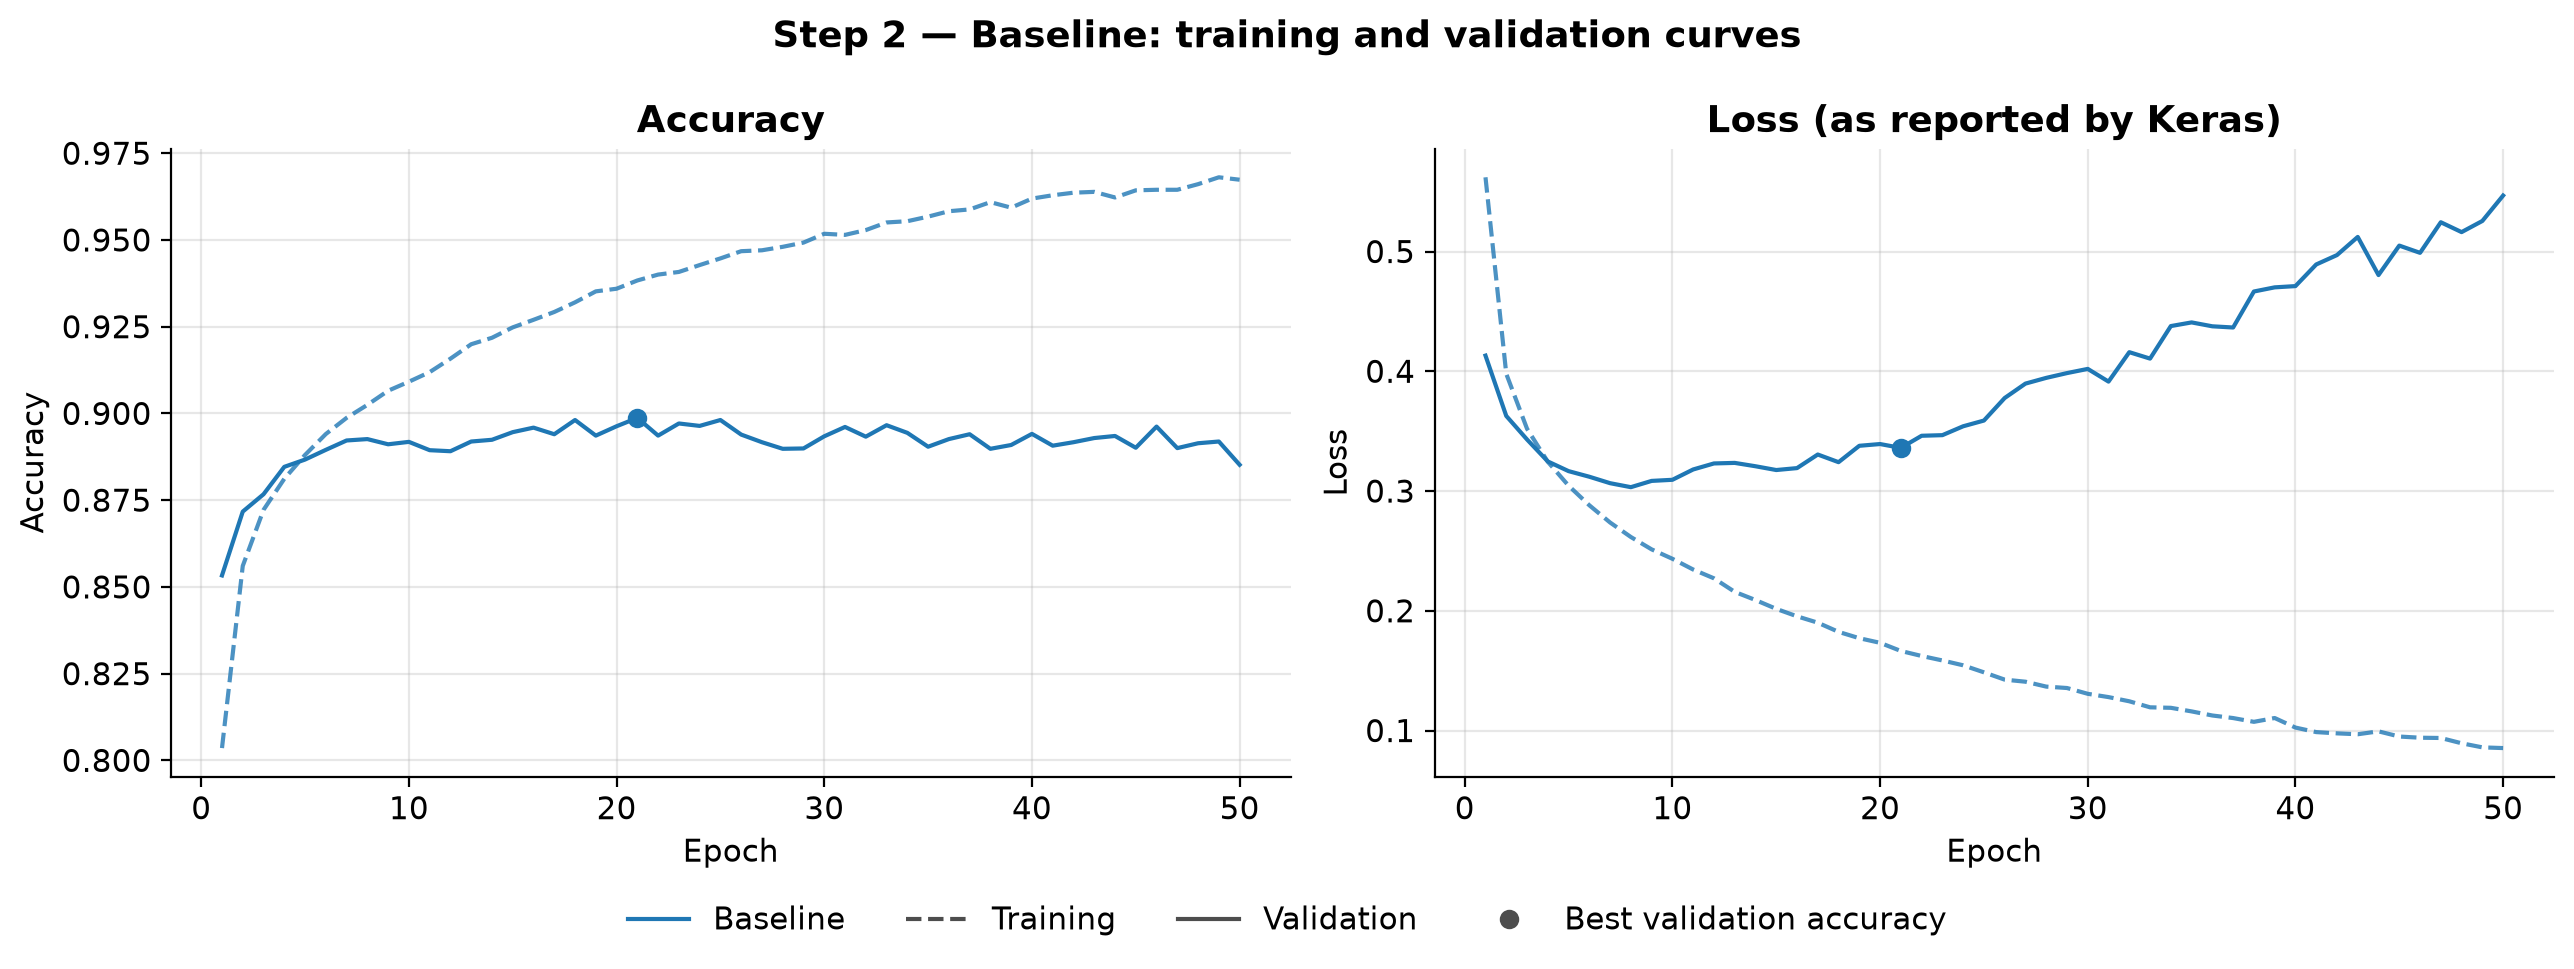

In [48]:
plot_curves([baseline], "Step 2 — Baseline: training and validation curves")

In [49]:
summary_table([baseline], data)

,Best epoch,Train acc,Val acc,Gap (train − val),"Train acc, dropout off",Train CE,Val CE,Hidden ‖W‖,Gap at epoch 50,Lowest val loss,Epoch of lowest val loss,Val loss at epoch 50
Baseline,21,0.9383,0.8987,0.0396,0.9321,0.1814,0.3306,45.4342,0.0822,0.3032,8,0.5467


### Reading the baseline

- **Learning.** The baseline learns appropriately. Before any update, its validation loss, 2.3598, is near the chance level for ten classes (ln 10 ≈ 2.30), and its validation accuracy is 0.0310 (Step 3's epoch-0 table). After one epoch, validation accuracy is 0.8533; it peaks at **0.8987 at epoch 21**. Training loss falls in every epoch but two (Step 3's stability table).

- **Validation accuracy plateaus early.** After the first several epochs it stops improving meaningfully and moves sideways to epoch 50, by a few tenths of a point per epoch. Training accuracy keeps climbing. The best epoch, 21, is one peak on a flat, noisy curve, not a clear turning point.

- **Validation loss shows overfitting.** Validation loss reaches its minimum, 0.3032, at **epoch 8**, then rises almost steadily to 0.5467 at epoch 50 while training loss keeps falling. This divergence is the standard sign of overfitting, and it appears in the loss well before the accuracy: at the retained epoch 21, validation cross-entropy is already 0.3306.

- **The gap widens.** Training minus validation accuracy is 0.0396 at the best epoch and 0.0822 at epoch 50. In inference mode, the retained weights score 0.9321 on the training images against 0.8987 on validation.

- **Verdict: reasonable generalization at the retained epoch, clear overfitting after it.** Training on to epoch 50 would cost 1.35 points of accuracy (0.8852 against 0.8987; Step 7's early-stopping table). Validation loss ends more than 0.24 above its epoch-8 minimum (0.5467 − 0.3032). The baseline does not underfit: its 118,282 parameters fit the 50,000 training images to 0.9321 accuracy within 21 epochs.

- **Limits.** One seed. The best epoch of a flat curve is itself noisy (see Step 6 on margins).

## Step 3 — Weight initialization

The only change from the baseline is `kernel_initializer="he_normal"` on both hidden layers; the output layer keeps the Keras default.

**What theory predicts.** A layer with fan-in $n$ and kernel variance $v$ gives pre-activations with $\mathbb{E}[z^2] = n\,v\,\mathbb{E}[x^2]$. ReLU zeroes the negative half, so $\mathbb{E}[\mathrm{relu}(z)^2] = \tfrac12\mathbb{E}[z^2]$. He initialization sets $v = 2/n$, so each ReLU layer passes on its input's second moment unchanged (He et al., 2015). Glorot uniform sets $v = 2/(n_\text{in} + n_\text{out})$ (Glorot & Bengio, 2010). Its derivation assumes activations symmetric around zero; under ReLU, it therefore shrinks the signal from layer to layer:

| Layer | $n_\text{in} \to n_\text{out}$ | Glorot variance | He variance | Predicted RMS ratio out/in, Glorot | Predicted RMS ratio out/in, He |
|---|---|---|---|---|---|
| `hidden_1` | 784 → 128 | 0.00219 | 0.00255 | 0.93 | 1.00 |
| `hidden_2` | 128 → 128 | 0.00781 | 0.01563 | 0.71 | 1.00 |

With only two hidden layers, the compounded difference is small. Adam also scales each parameter's step by its own gradient history, which further reduces sensitivity to the initial scale. The working hypothesis is therefore that He initialization mainly changes the first epochs; the runs below test it.

The cell below first checks the prediction on real inputs, with each model built from the run's seed and not yet trained.

In [50]:
def predicted_ratio(initializer: str, fan_in: int, fan_out: int) -> float:
    """Predicted RMS(out) / RMS(in) of one ReLU layer at initialization."""
    variance = {"glorot_uniform": 2 / (fan_in + fan_out), "he_normal": 2 / fan_in}[initializer]
    return float(np.sqrt(0.5 * fan_in * variance))


def rms(values: np.ndarray) -> float:
    """Root mean square over all entries."""
    return float(np.sqrt(np.mean(values**2)))


def activation_scale(config: Config, X: np.ndarray) -> dict[str, float]:
    """Measured vs predicted RMS ratio of each hidden layer's ReLU output at initialization."""
    keras.utils.set_random_seed(SEED)
    model = build_model(config)
    probe = keras.Model(model.inputs, [model.get_layer(f"hidden_{i}").output for i in (1, 2)])
    hidden_1, hidden_2 = probe.predict(X, batch_size=1024, verbose=0)
    return {
        "RMS input": rms(X),
        "RMS hidden_1": rms(hidden_1),
        "RMS hidden_2": rms(hidden_2),
        "hidden_1 / input, measured": rms(hidden_1) / rms(X),
        "hidden_1 / input, predicted": predicted_ratio(config.initializer, 784, HIDDEN_UNITS),
        "hidden_2 / hidden_1, measured": rms(hidden_2) / rms(hidden_1),
        "hidden_2 / hidden_1, predicted": predicted_ratio(config.initializer, HIDDEN_UNITS, HIDDEN_UNITS),
    }


pd.DataFrame({config.name: activation_scale(config, data.val.X) for config in (BASELINE, HE)}).T

,RMS input,RMS hidden_1,RMS hidden_2,"hidden_1 / input, measured","hidden_1 / input, predicted","hidden_2 / hidden_1, measured","hidden_2 / hidden_1, predicted"
Baseline,0.453,0.4192,0.2695,0.9255,0.9272,0.6429,0.7071
He init,0.453,0.4650,0.4589,1.0266,1.0000,0.9869,1.0000


In [51]:
he = train(HE, data)

He init: best validation accuracy 0.8968 at epoch 31/50 (38 s)


### The first epochs

Epoch 0 is the untrained model; training metrics start at epoch 1.

In [52]:
def early_epochs(runs: list[Run], n: int = 5) -> pd.DataFrame:
    """Validation metrics before training (epoch 0), then all four metrics for the first `n` epochs."""
    names = {"loss": "Train loss", "accuracy": "Train acc", "val_loss": "Val loss", "val_accuracy": "Val acc"}
    frames = {}
    for run in runs:
        start = pd.DataFrame(run.initial, index=pd.Index([0], name="epoch"))
        first = pd.concat([start, run.history.loc[1:n]]).rename(columns=names)
        frames[run.config.name] = first[list(names.values())]
    return pd.concat(frames, axis=1)


early_epochs([baseline, he])

Baseline                               He init                     \
      Train loss Train acc Val loss Val acc Train loss Train acc Val loss   
epoch                                                                       
0            NaN       NaN   2.3598  0.0310        NaN       NaN   2.3802   
1         0.5620    0.8035   0.4131  0.8533     0.5487    0.8083   0.4243   
2         0.3979    0.8560   0.3627  0.8717     0.3955    0.8572   0.3589   
3         0.3520    0.8722   0.3430  0.8767     0.3521    0.8710   0.3350   
4         0.3244    0.8812   0.3247  0.8846     0.3246    0.8814   0.3264   
5         0.3045    0.8880   0.3166  0.8867     0.3043    0.8890   0.3250   

               
      Val acc  
epoch          
0      0.1347  
1      0.8480  
2      0.8755  
3      0.8826  
4      0.8848  
5      0.8846

### Convergence and stability

- **Convergence speed:** the first epoch at which validation accuracy reaches `CONVERGENCE_TARGET`, a level both models pass.
- **Stability:** how many epochs training loss *rose* from the previous epoch, and the standard deviation of the epoch-to-epoch change in validation accuracy. Lower means smoother.

In [53]:
CONVERGENCE_TARGET = 0.88


def convergence_profile(run: Run) -> dict[str, object]:
    """Speed, stability, and peak of one run's validation curve."""
    history = run.history
    reached = history.index[history["val_accuracy"] >= CONVERGENCE_TARGET]
    return {
        "Val loss before training": run.initial["val_loss"],
        "Epoch-1 train loss": history["loss"].iloc[0],
        "Epoch-1 val acc": history["val_accuracy"].iloc[0],
        f"First epoch val acc ≥ {CONVERGENCE_TARGET:.2f}": int(reached[0]) if len(reached) else None,
        "Train-loss rises (epochs)": int((history["loss"].diff() > 0).sum()),
        "Std of val-acc change": history["val_accuracy"].diff().std(),
        "Best val acc": best_val_accuracy(run),
        "Best epoch": run.best_epoch,
    }


pd.DataFrame.from_dict(
    {run.config.name: convergence_profile(run) for run in (baseline, he)}, orient="index"
).astype({f"First epoch val acc ≥ {CONVERGENCE_TARGET:.2f}": "Int64"})

,Val loss before training,Epoch-1 train loss,Epoch-1 val acc,First epoch val acc ≥ 0.88,Train-loss rises (epochs),Std of val-acc change,Best val acc,Best epoch
Baseline,2.3598,0.5620,0.8533,4,2,0.0041,0.8987,21
He init,2.3802,0.5487,0.8480,3,6,0.0047,0.8968,31


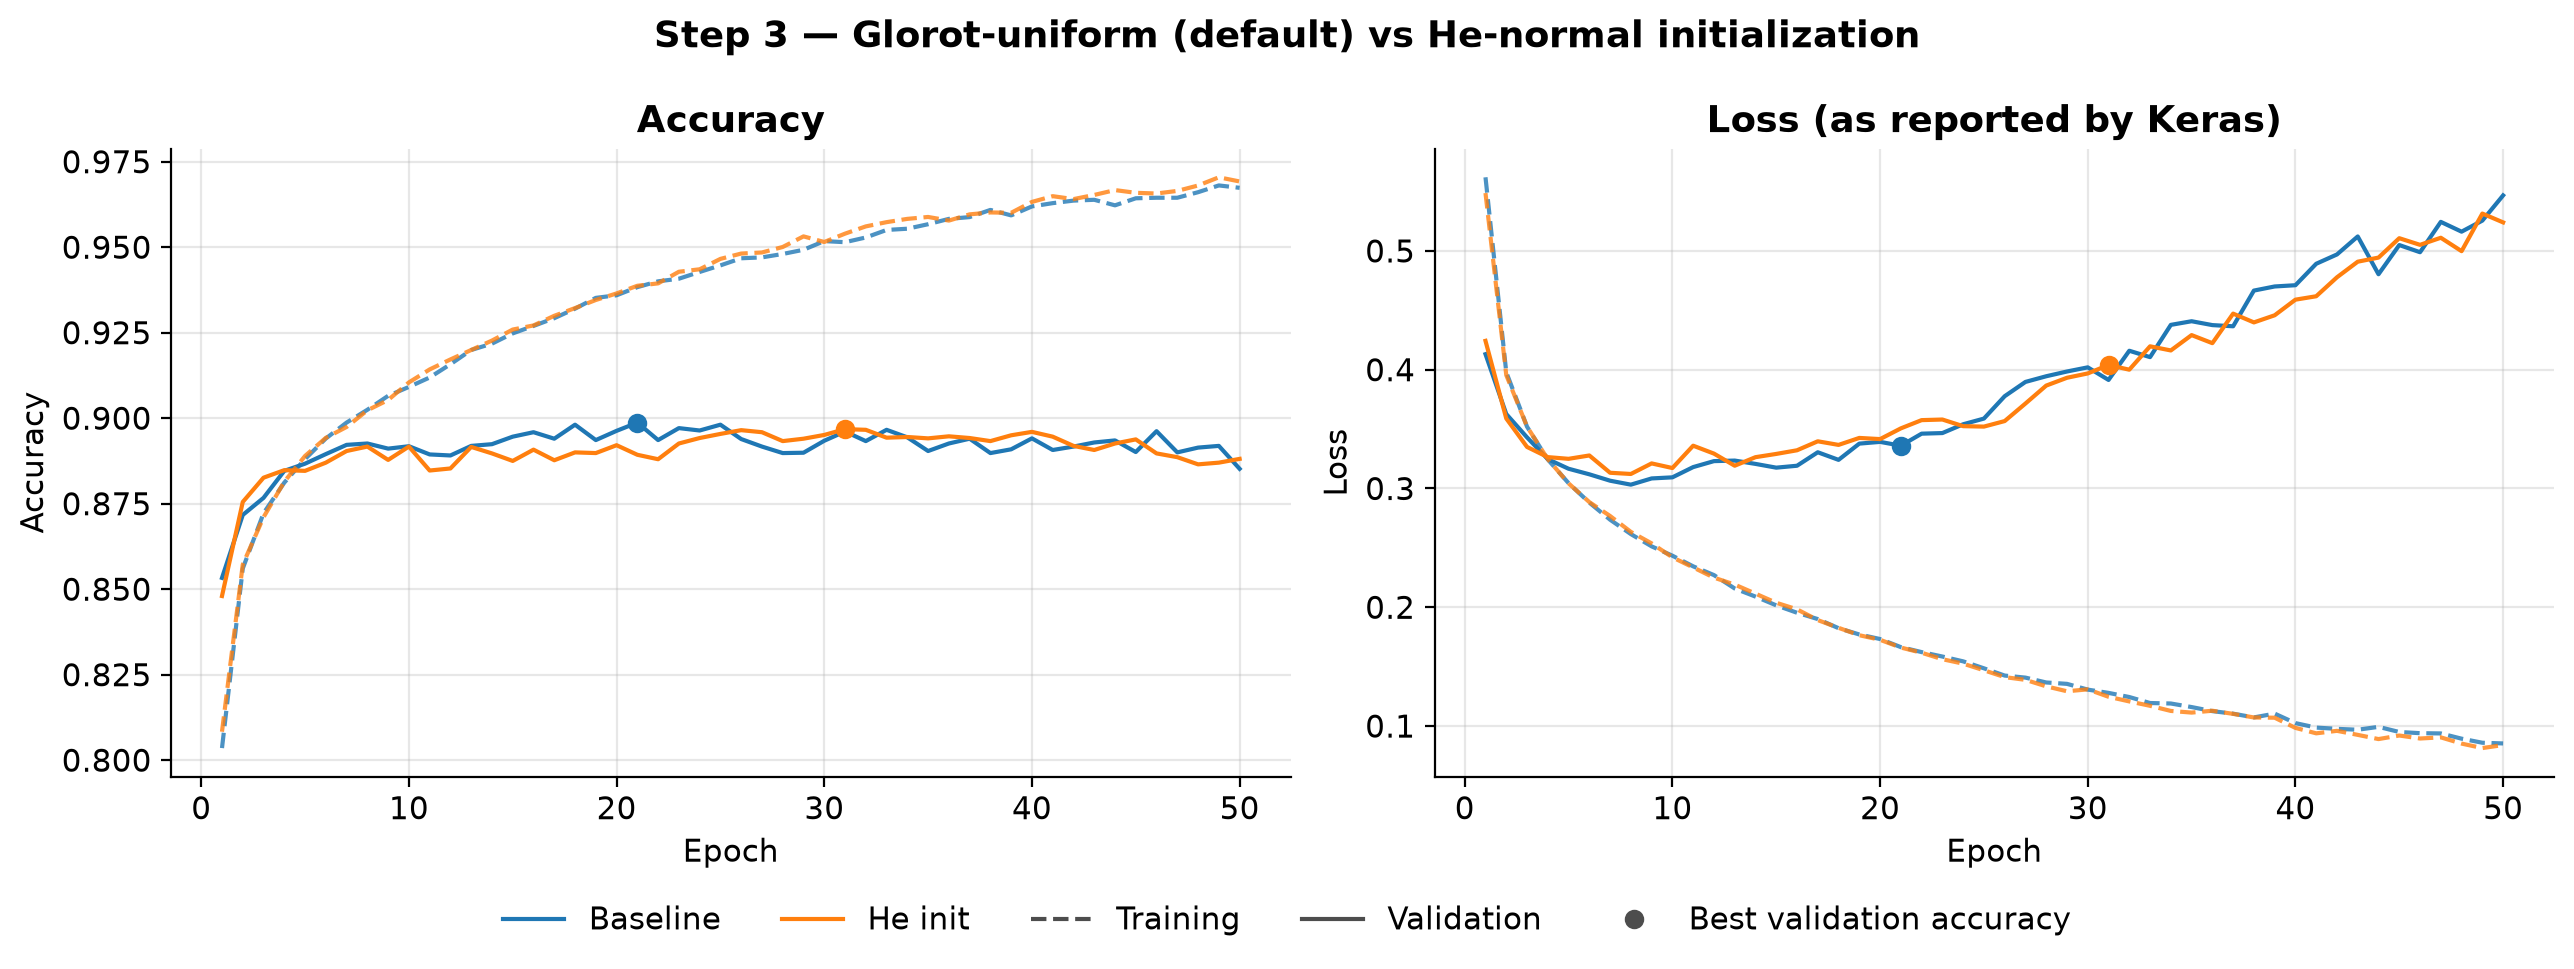

In [54]:
plot_curves([baseline, he], "Step 3 — Glorot-uniform (default) vs He-normal initialization")

### Did initialization matter?

**Direct answer: He init changed the first few epochs slightly and made no meaningful difference to validation performance or to overfitting.**

- **Activation scale matches the theory.** At initialization, Glorot uniform shrinks the signal layer by layer. The measured RMS ratios are 0.9255 for `hidden_1` and 0.6429 for `hidden_2` (predicted 0.9272 and 0.7071), so `hidden_2`'s RMS falls to 0.2695 from an input RMS of 0.453. He init preserves the signal: its ratios are 1.0266 and 0.9869 against a predicted 1.00, and `hidden_2`'s RMS stays at 0.4589. Glorot's second-layer shortfall exceeds the prediction, plausibly because the measurement uses one weight draw on correlated images rather than the average the prediction assumes (untested).
- **First epochs.** Both models start at chance-level validation loss, 2.3598 (Glorot) and 2.3802 (He). He's first epoch is marginally better on training data (loss 0.5487 against 0.5620, accuracy 0.8083 against 0.8035) but marginally worse on validation (0.8480 against 0.8533). From epoch 4 on, the two validation curves cross repeatedly (0.8846 and 0.8848 at epoch 4, 0.8867 and 0.8846 at epoch 5) and stay within about a point of each other.
- **Convergence speed.** He reaches 0.88 validation accuracy at epoch 3, Glorot at epoch 4. That single epoch is the only speed difference.
- **Stability.** Neither run diverges or oscillates widely. He has more epochs in which training loss rose (6 against 2). Its epoch-to-epoch spread in validation accuracy is also slightly larger (standard deviation 0.0047 against 0.0041).
- **Validation performance and overfitting.** Best validation accuracy is 0.8968 at epoch 31 for He, against 0.8987 at epoch 21 for Glorot. The 0.19-point difference is below one standard error (about 0.30 points; Step 6), so the runs tie, and on flat plateaus the best-epoch positions mostly reflect noise. Overfitting is also unchanged: both validation losses bottom out at epoch 8 (0.3032 and 0.3122), the epoch-50 gaps are 0.0822 and 0.0811, and the per-epoch gap curves overlap (Step 7). He's larger gap at its best epoch (0.0572 against 0.0396) reflects a later best epoch on the same rising curve, not more overfitting.
- **Why so little effect.** The result matches the working hypothesis. With two hidden layers, Glorot's compounded shrinkage is modest, and Adam's per-parameter step scaling offsets much of the difference in initial scale. He init matters most in deep ReLU stacks, where a per-layer factor such as 0.7 compounds over many layers.
- **Limits.** One seed per initializer (see Step 6 on margins).

## Step 4 — L2 regularization

Starting from He init, L2 is applied to both hidden kernels and not to the output layer. The penalty $\lambda \sum w^2$ adds $2\lambda w$ to each weight's gradient, pulling every weight toward zero at each step. A weight stays large only where it reduces the data loss enough to pay for the penalty, which limits how sharply the network can fit individual training images. Two strengths an order of magnitude apart, $\lambda = 0.001$ and $\lambda = 0.01$, show both sides of the trade-off.

Under Adam, an L2 term in the loss is rescaled by the adaptive step like any other gradient, so it is not identical to decoupled weight decay (Loshchilov & Hutter, 2019). It still regularizes; the `Hidden ‖W‖` column shows by how much.

In [55]:
l2_runs = [train(config, data) for config in L2_CONFIGS]

He + L2 0.001: best validation accuracy 0.8920 at epoch 48/50 (41 s)
He + L2 0.01: best validation accuracy 0.8667 at epoch 45/50 (39 s)


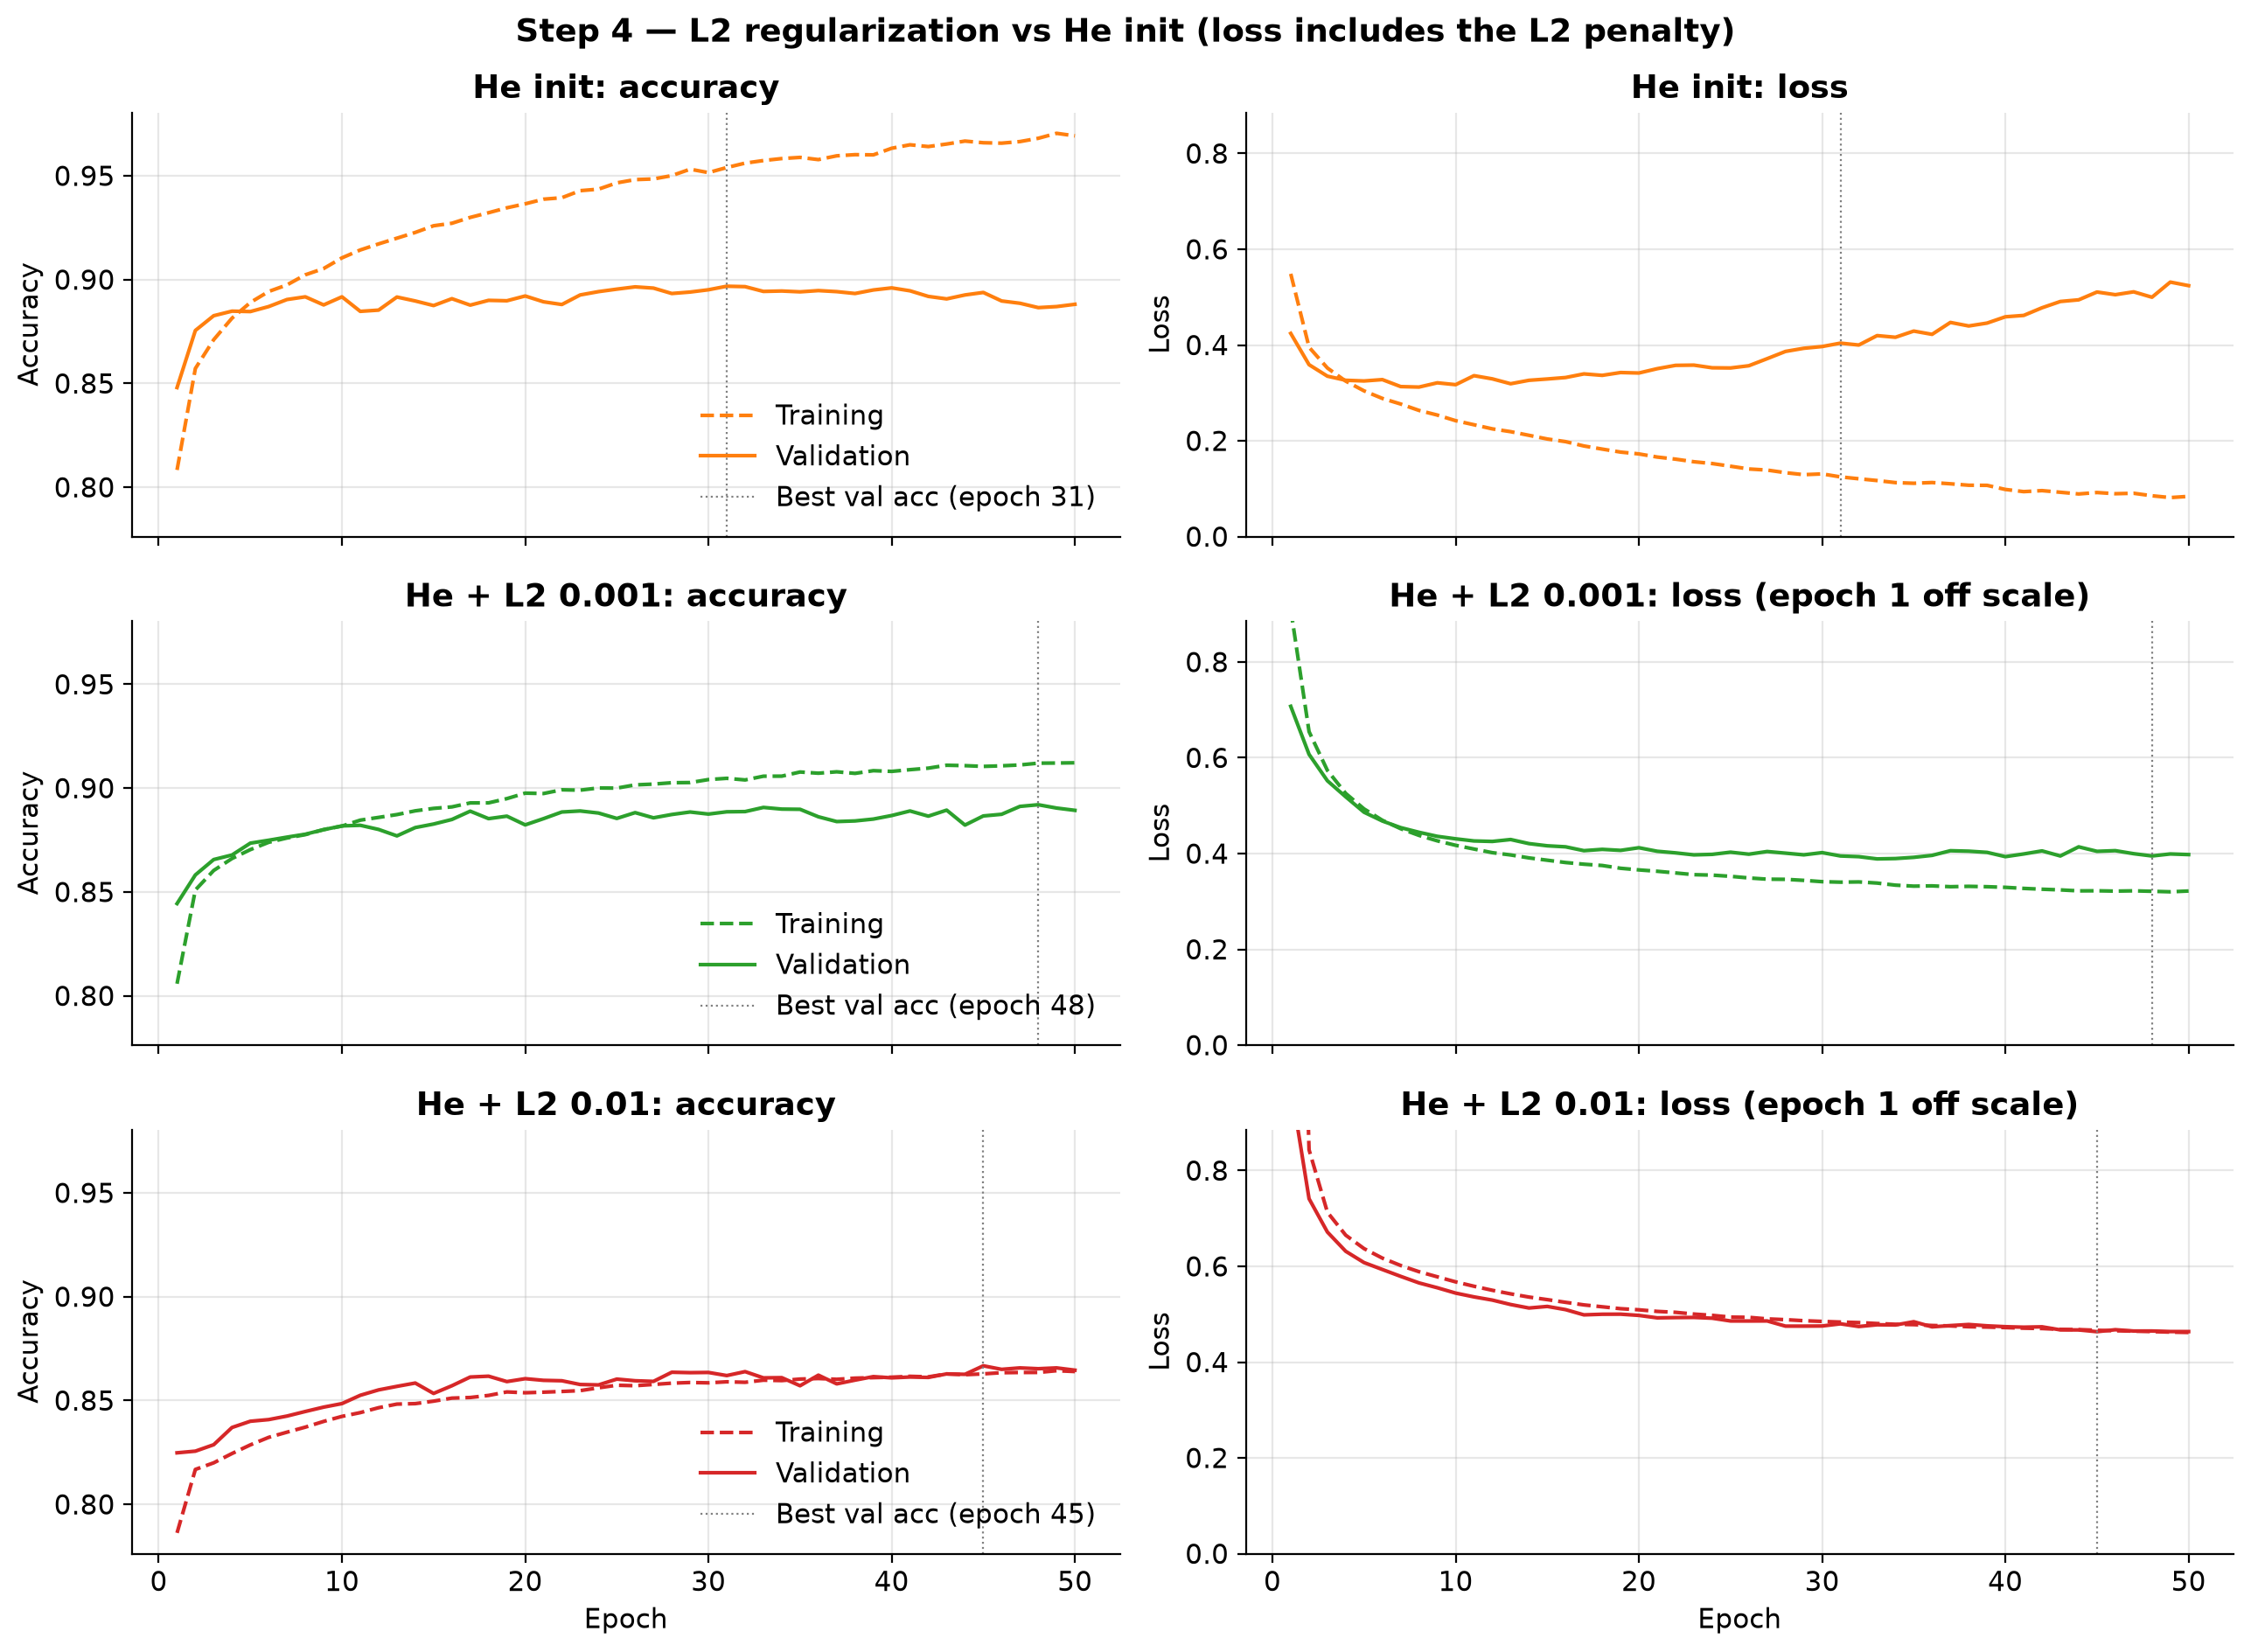

In [56]:
plot_grid([he, *l2_runs], "Step 4 — L2 regularization vs He init (loss includes the L2 penalty)")

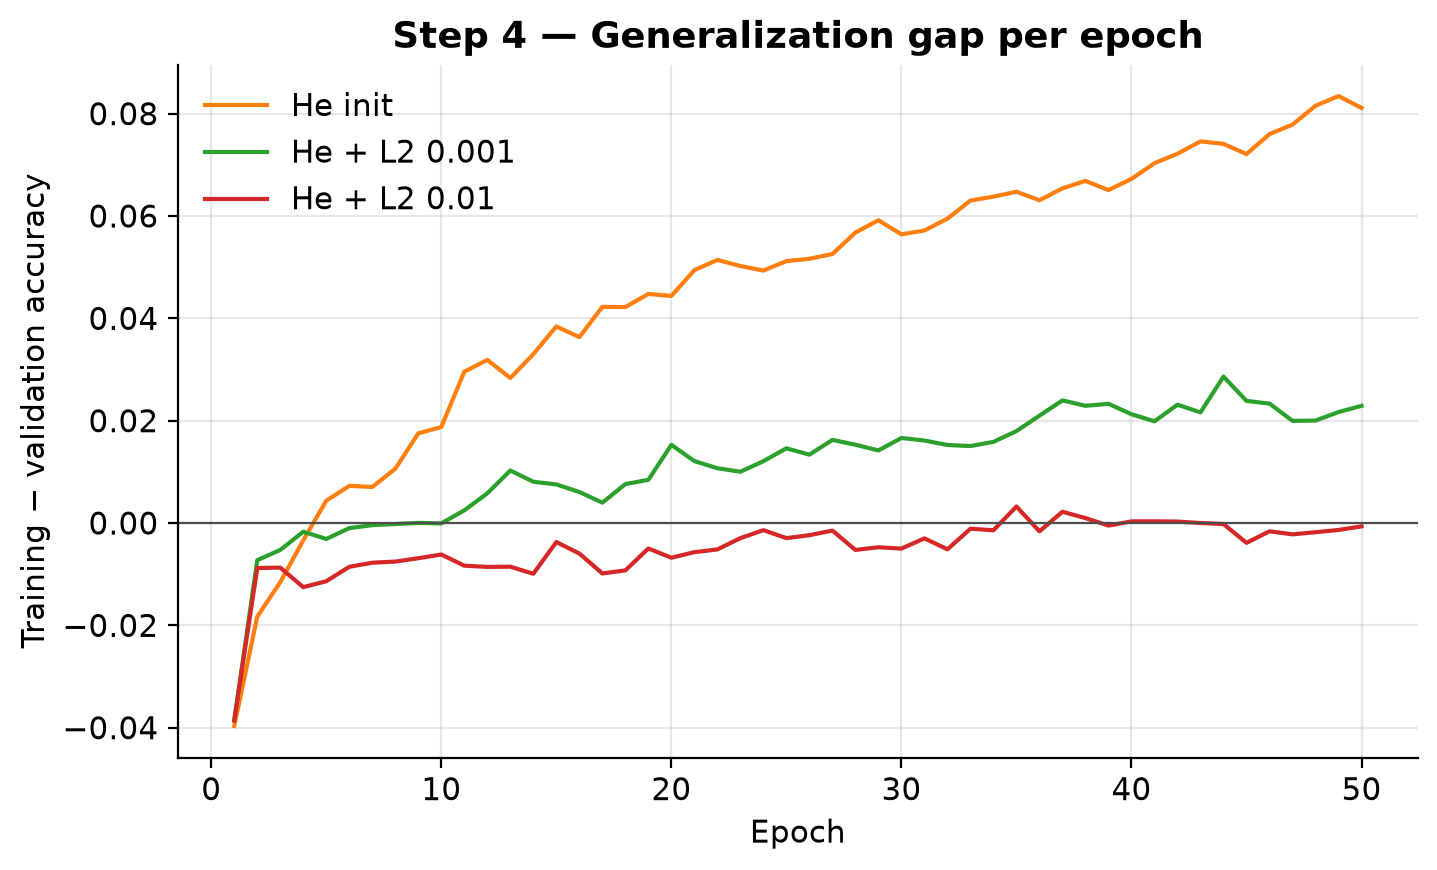

In [57]:
plot_gap([he, *l2_runs], "Step 4 — Generalization gap per epoch")

In [58]:
summary_table([he, *l2_runs], data)

,Best epoch,Train acc,Val acc,Gap (train − val),"Train acc, dropout off",Train CE,Val CE,Hidden ‖W‖,Gap at epoch 50,Lowest val loss,Epoch of lowest val loss,Val loss at epoch 50
He init,31,0.9540,0.8968,0.0572,0.9389,0.1640,0.3908,56.2936,0.0811,0.3122,8,0.5240
He + L2 0.001,48,0.9120,0.8920,0.0200,0.9098,0.2440,0.3134,9.0284,0.0229,0.3888,33,0.3979
He + L2 0.01,45,0.8628,0.8667,-0.0039,0.8638,0.3722,0.3757,2.9633,-0.0007,0.4635,45,0.4637


In [59]:
best_l2 = best_of(l2_runs)
margin = best_val_accuracy(best_l2) - min(best_val_accuracy(run) for run in l2_runs)
print(f"Better L2 model on validation: {best_l2.config.name} (by {100 * margin:.2f} percentage points)")

Better L2 model on validation: He + L2 0.001 (by 2.53 percentage points)


### Effect of L2

Keras adds the penalty $\lambda\sum w^2$ to the reported loss, so the λ = 0.01 run starts with a much higher training loss and its loss curves sit above He init's even where its predictions are no worse. Losses are therefore compared through the penalty-free `Train CE` and `Val CE` columns, not the plotted loss.

- **The gap narrows sharply.** At the best epoch, training minus validation accuracy falls from 0.0572 (He init) to 0.0200 at λ = 0.001 and −0.0039 at λ = 0.01; at epoch 50, it falls from 0.0811 to 0.0229 and −0.0007. In the gap plot, the gap without L2 keeps widening through epoch 50, at λ = 0.001 it grows slowly, and at λ = 0.01 it stays at or slightly below zero.
- **Training accuracy decreases.** Training accuracy drops from 0.9540 to 0.9120 and 0.8628, and full-network training accuracy from 0.9389 to 0.9098 and 0.8638. The penalty keeps the network from fitting training images as closely: the hidden-kernel norm falls from 56.2936 to 9.0284 and 2.9633.
- **λ = 0.001 is not too weak.** Validation loss no longer climbs after an early minimum: it is lowest at epoch 33 (0.3888, penalty included) and ends at 0.3979, whereas He init's rises from 0.3122 at epoch 8 to 0.5240. Penalty-free validation cross-entropy at the best epoch is 0.3134, against 0.3908. Validation accuracy does not improve, though: 0.8920 against 0.8968, a 0.48-point drop that Step 6's half-point convention counts as a tie. The late best epoch, 48, is one peak on a nearly flat second half, not continued improvement.
- **λ = 0.01 is too strong.** Training and validation accuracy both fall, to 0.8628 and 0.8667, while the gap stays near zero. Validation cross-entropy (0.3757) is worse than λ = 0.001's and only slightly better than He init's 0.3908. He init's figure, though, is measured after its validation loss had risen well above its epoch-8 minimum. λ = 0.01 underfits: the penalty caps the weights (norm 2.9633) so hard that the network cannot fit the training set, let alone overfit it.
- **Better balance: λ = 0.001.** It removes most of the overfitting (gap 0.0200; no late rise in validation loss) at a validation-accuracy cost within noise, while λ = 0.01 gives up a further 2.53 points.
- **Limits.** The two strengths bracket the useful range but leave the optimum between them untested. L2 inside Adam differs from decoupled weight decay (Step 4 introduction), so these strengths would not transfer directly to AdamW.

## Step 5 — Dropout

Starting again from He init without L2, a `Dropout` layer follows each hidden layer. During training, each hidden activation is zeroed with probability $p$ and the survivors are scaled by $1/(1-p)$, so the expected activation is unchanged. Each mini-batch therefore trains a different thinned sub-network, and no unit can rely on a particular partner being present (Srivastava et al., 2014). At validation and test time, dropout is off: every unit is active and nothing is scaled. Two rates are tested. Rate 0.2 is a light setting that removes one hidden activation in five. Rate 0.4 is twice as strong and close to the 0.5 that Srivastava et al. used for hidden layers; it tests whether stronger dropout starts to cost fit (underfitting) rather than only narrowing the gap.

**Why training accuracy can fall below validation accuracy.** Keras's training accuracy for an epoch comes from the thinned networks, averaged over the epoch while the weights improve. Validation accuracy comes from the full network at the end of the epoch. A handicapped network measured during the epoch can therefore score below the full network measured at its end, even on data it has seen, and more so as $p$ grows. The shortfall is a measurement artifact, not evidence that the model fits validation data better than training data. `Train acc, dropout off` removes the artifact by evaluating the full network on the training images.

In [60]:
dropout_runs = [train(config, data) for config in DROPOUT_CONFIGS]

He + dropout 0.2: best validation accuracy 0.9031 at epoch 41/50 (43 s)
He + dropout 0.4: best validation accuracy 0.8977 at epoch 50/50 (42 s)


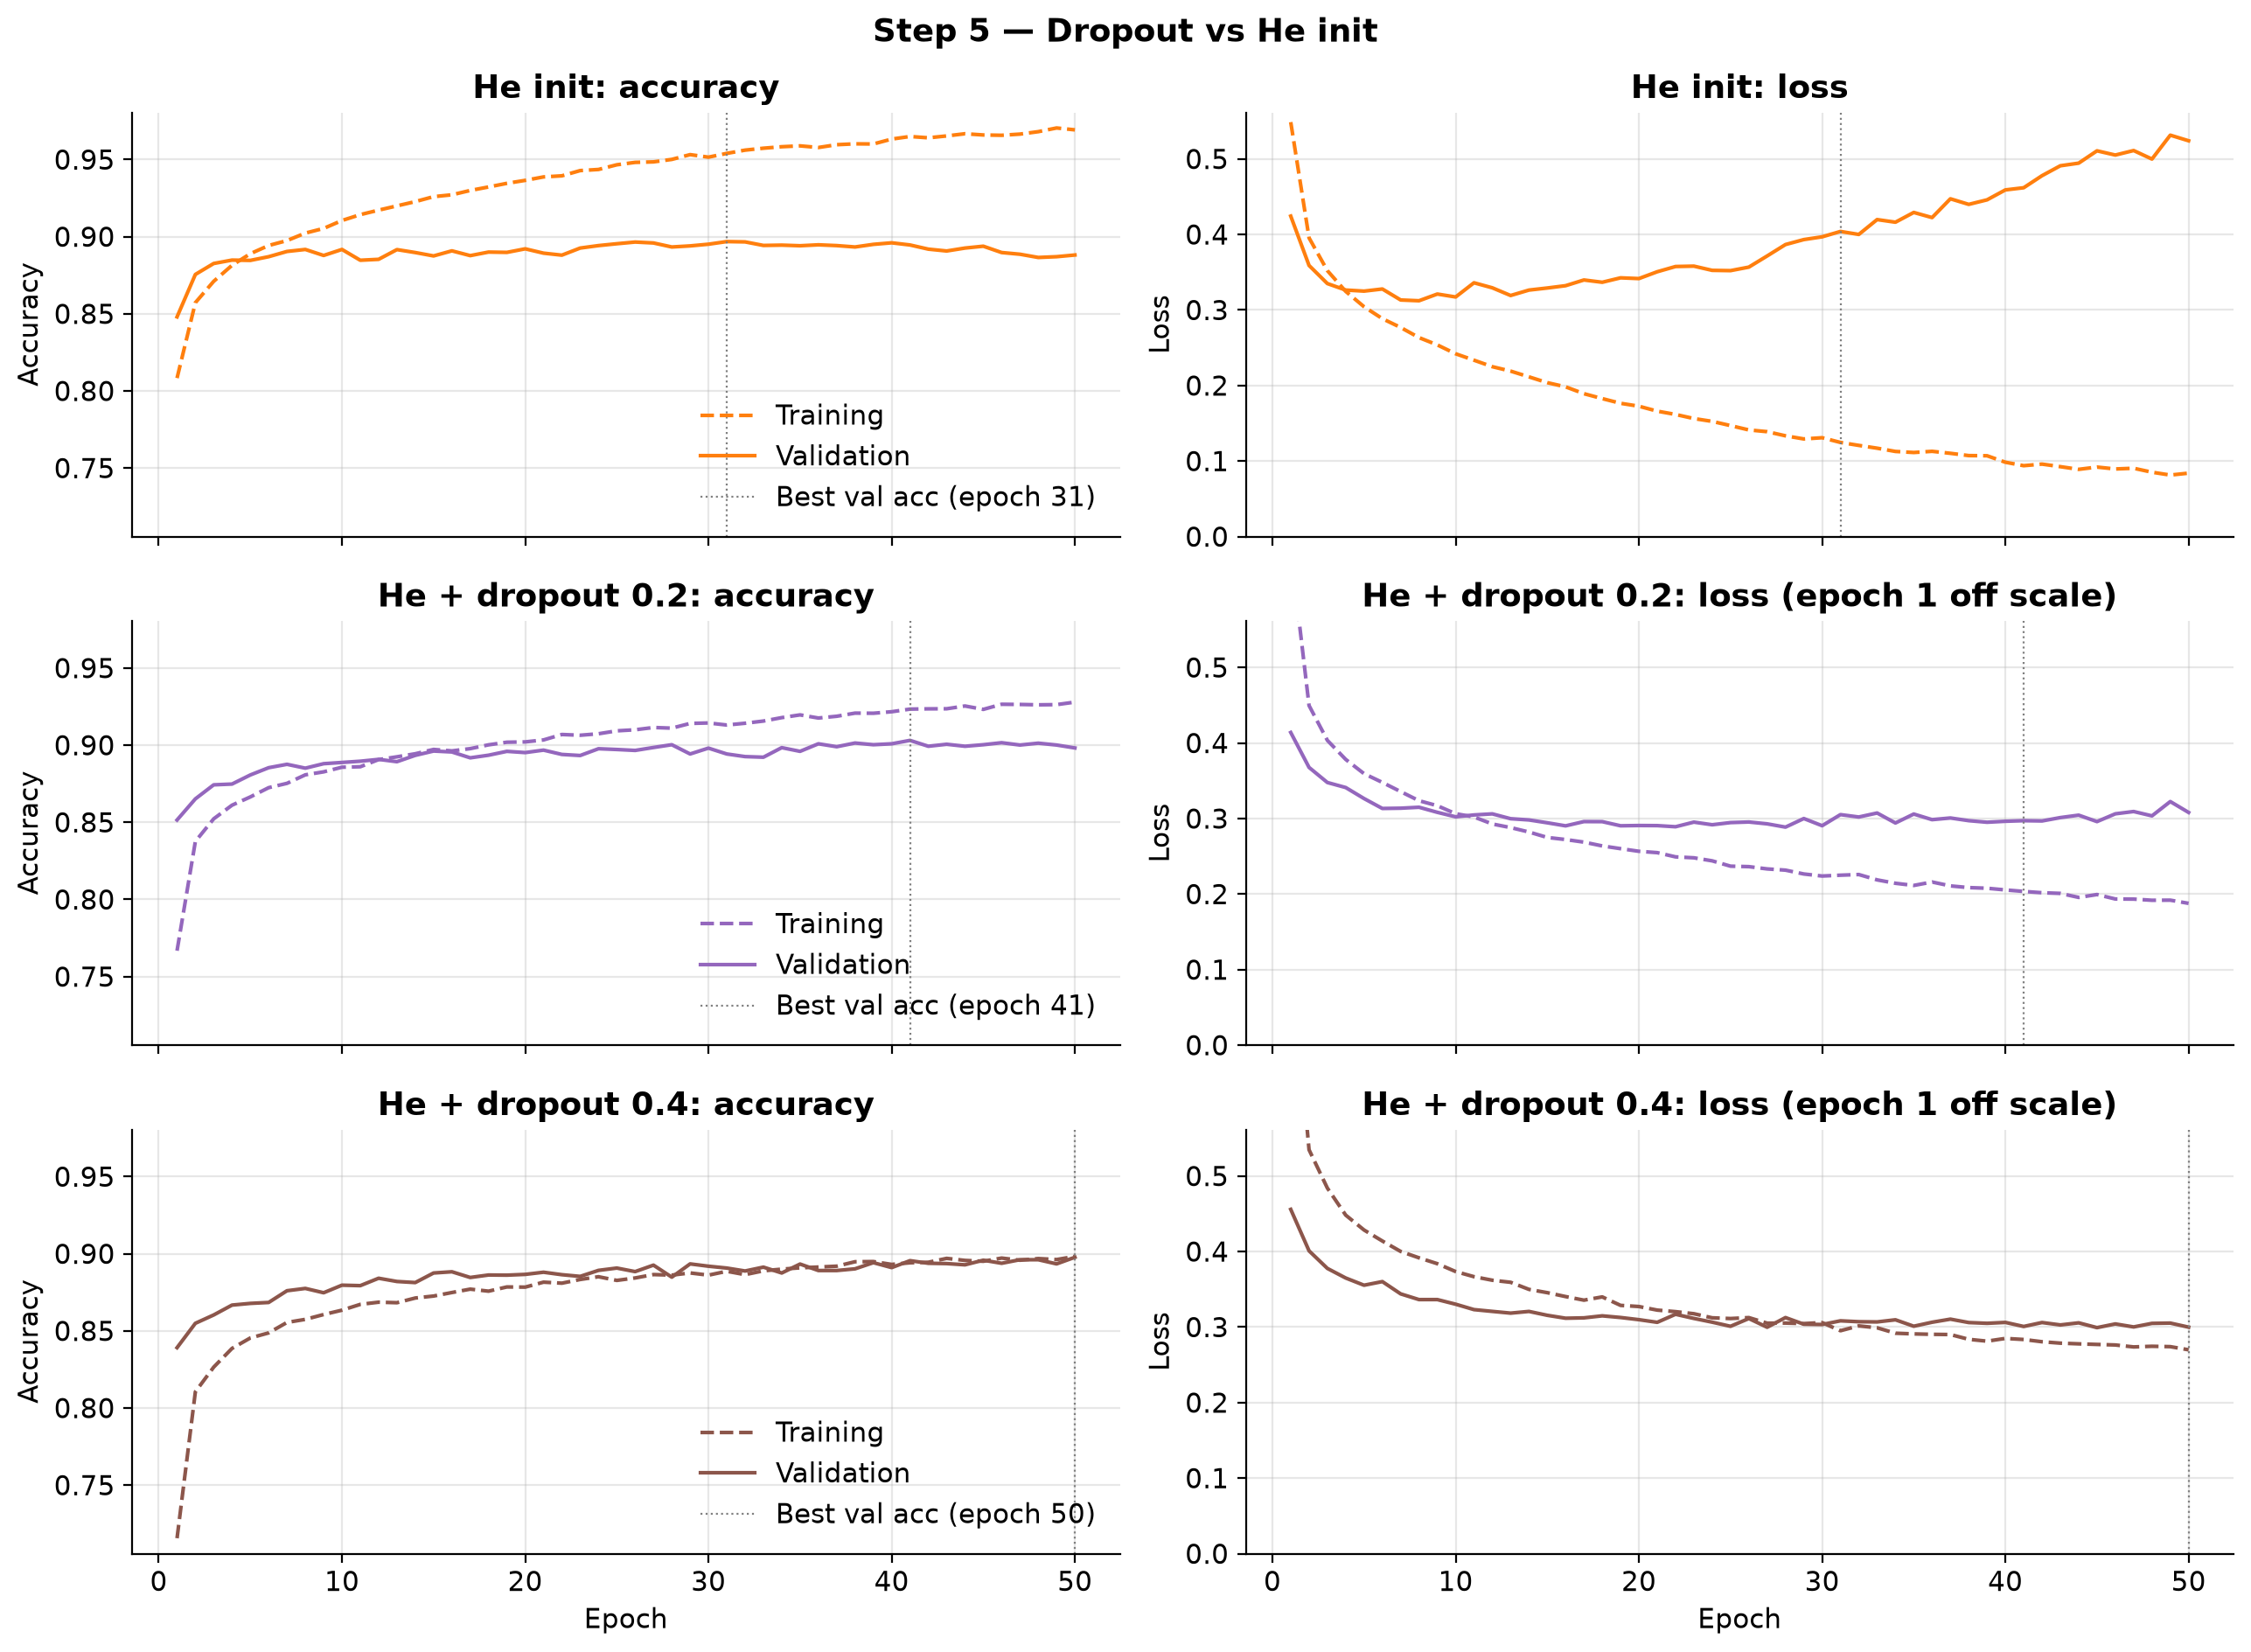

In [61]:
plot_grid([he, *dropout_runs], "Step 5 — Dropout vs He init")

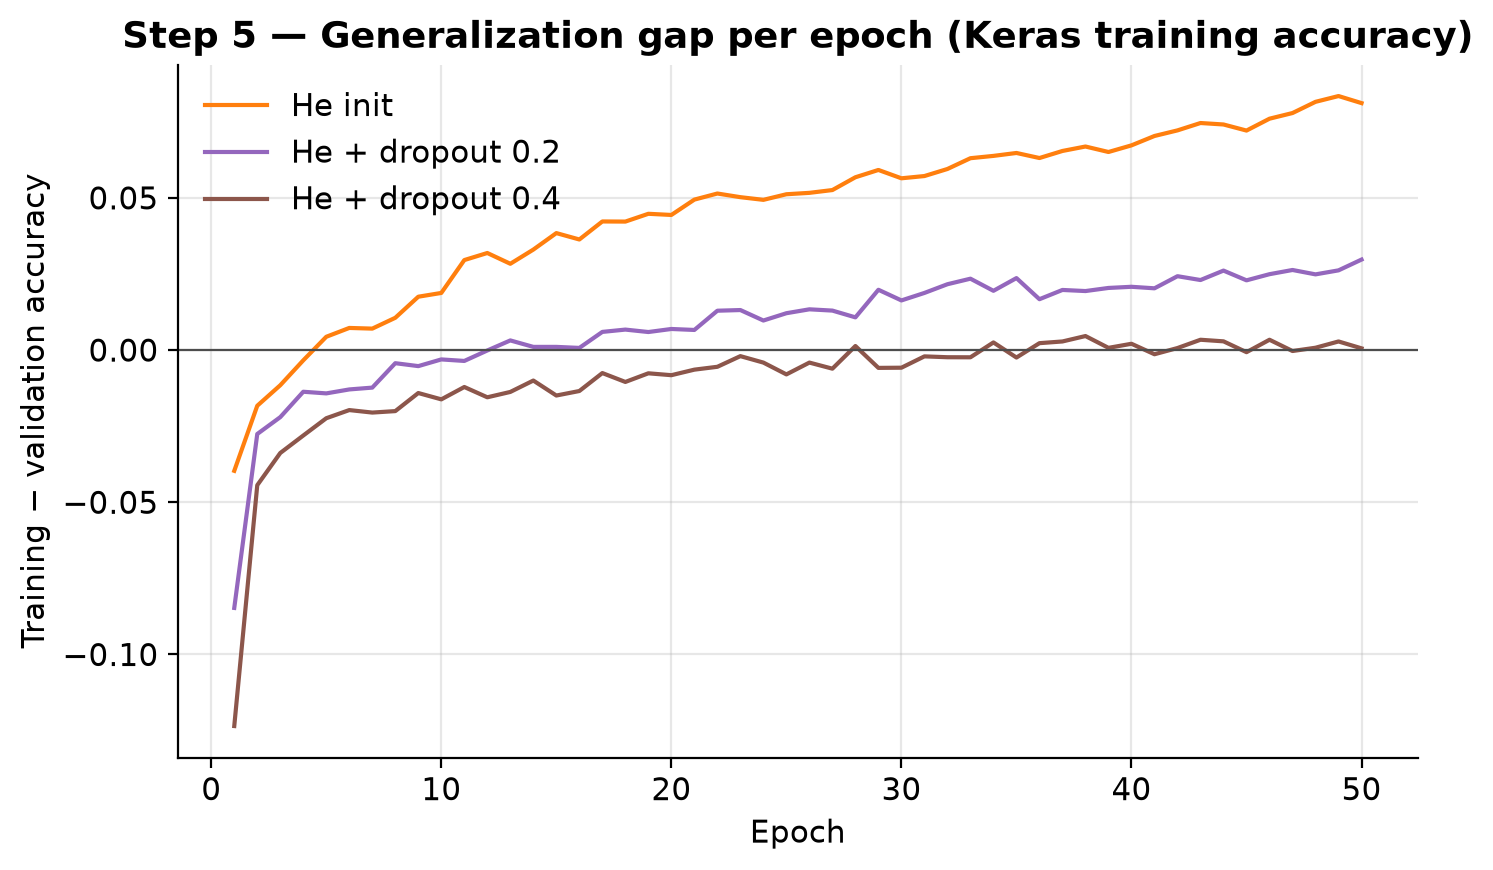

In [62]:
plot_gap([he, *dropout_runs], "Step 5 — Generalization gap per epoch (Keras training accuracy)")

In [63]:
# The first epochs: Keras's training accuracy (dropout active) against validation accuracy (dropout off).
early_epochs([he, *dropout_runs])

He init                            He + dropout 0.2            \
      Train loss Train acc Val loss Val acc       Train loss Train acc   
epoch                                                                    
0            NaN       NaN   2.3802  0.1347              NaN       NaN   
1         0.5487    0.8083   0.4243  0.8480           0.6555    0.7668   
2         0.3955    0.8572   0.3589  0.8755           0.4495    0.8376   
3         0.3521    0.8710   0.3350  0.8826           0.4034    0.8523   
4         0.3246    0.8814   0.3264  0.8848           0.3782    0.8611   
5         0.3043    0.8890   0.3250  0.8846           0.3594    0.8665   

                       He + dropout 0.4                             
      Val loss Val acc       Train loss Train acc Val loss Val acc  
epoch                                                               
0       2.3611  0.1287              NaN       NaN   2.3611  0.1287  
1       0.4139  0.8515           0.7977    0.7156   0.4558  0.8391  
2       0.3676  0.8652           0.5346    0.8105   0.4009  0.8549  
3       0.3477  0.8743           0.4839    0.8265   0.3776  0.8603  
4       0.3410  0.8748           0.4482    0.8386   0.3649  0.8667  
5       0.3264  0.8807           0.4285    0.8454   0.3554  0.8678

In [64]:
summary_table([he, *dropout_runs], data)

,Best epoch,Train acc,Val acc,Gap (train − val),"Train acc, dropout off",Train CE,Val CE,Hidden ‖W‖,Gap at epoch 50,Lowest val loss,Epoch of lowest val loss,Val loss at epoch 50
He init,31,0.9540,0.8968,0.0572,0.9389,0.1640,0.3908,56.2936,0.0811,0.3122,8,0.5240
He + dropout 0.2,41,0.9234,0.9031,0.0203,0.9351,0.1661,0.2948,59.1528,0.0297,0.2886,28,0.3080
He + dropout 0.4,50,0.8983,0.8977,0.0006,0.9230,0.2024,0.2963,62.5130,0.0006,0.2992,45,0.2999


In [65]:
best_dropout = best_of(dropout_runs)
margin = best_val_accuracy(best_dropout) - min(best_val_accuracy(run) for run in dropout_runs)
print(
    f"Better dropout model on validation: {best_dropout.config.name} "
    f"(by {100 * margin:.2f} percentage points)"
)

Better dropout model on validation: He + dropout 0.2 (by 0.54 percentage points)


### Effect of dropout

- **Training accuracy: Keras's number falls, the full network's barely does.** At the best epoch, Keras's training accuracy falls from 0.9540 (He init) to 0.9234 at rate 0.2 and 0.8983 at rate 0.4. It is measured on the thinned networks, so it understates the fit. Full-network training accuracy is 0.9389, 0.9351, and 0.9230, so at rate 0.2 the network fits the training data almost as well as without dropout.
- **Validation accuracy rises at 0.2.** Validation accuracy is 0.9031 at rate 0.2 (epoch 41) and 0.8977 at 0.4 (epoch 50), against 0.8968 for He init. The 0.2 gain, 0.63 points, is just above Step 6's half-point convention and about 1.5 standard errors of a difference (see Step 6 on margins). The 0.4 result ties with He init. Validation cross-entropy at the best epoch is lower at both rates (0.2948 and 0.2963, against 0.3908), but He init's figure comes after its validation loss had risen from its epoch-8 minimum. Compared at their minima, the values are closer: 0.2886 and 0.2992, against 0.3122.
- **The gap narrows, and overfitting in the loss mostly disappears.** Keras's gap falls from 0.0572 to 0.0203 and 0.0006 at the best epoch, and from 0.0811 to 0.0297 and 0.0006 at epoch 50. The like-for-like gap, full-network training accuracy minus validation accuracy, falls from 0.0421 to 0.0320 and 0.0253. Validation loss reaches its minimum later, at epoch 28 (rate 0.2) and epoch 45 (rate 0.4), and ends at 0.3080 and 0.2999; He init's climbs to 0.5240.
- **Does 0.4 underfit? Mildly, within 50 epochs.** Its full-network training accuracy (0.9230) and validation accuracy (0.8977) are both below rate 0.2's. It peaks at the last epoch, 50, with validation loss still near its minimum, so part of the shortfall is likely slower convergence rather than a hard limit. A longer budget is not tested.
- **Better rate: 0.2.** It has the highest validation accuracy of any run, 0.54 points above rate 0.4, and the lowest validation cross-entropy. Its gap is much smaller than He init's, and it keeps nearly all of the training fit.
- **Training accuracy below validation accuracy.** Keras's training accuracy starts below validation accuracy in every run, because epoch 1's running average includes the nearly untrained start (He init: 0.8083 against 0.8480). Without dropout or L2, the order flips within five epochs (He init at epoch 5: 0.8890 against 0.8846). Dropout makes the shortfall larger and longer-lasting: at epoch 5, training accuracy is 0.8665 against 0.8807 at rate 0.2 and 0.8454 against 0.8678 at rate 0.4. At 0.4 the two are still level at the best epoch (0.8983 against 0.8977). The cause is the artifact described in the Step 5 introduction: Keras scores thinned sub-networks averaged over the epoch, while validation scores the full network at its end. Full-network training accuracy removes the artifact: at 0.4 it is 0.9230, 2.53 points above validation. The training data are still fit better; dropout only hides that from Keras's number.
- **A second measurement effect.** Without dropout, Keras's training accuracy sits *above* full-network training accuracy at the best epoch: 0.9540 against 0.9389 for He init, 0.9383 against 0.9321 for the baseline. The notebook does not isolate the cause. Because the two measures can differ by more than a point in either direction, `Train acc, dropout off` is the fair comparison with validation.
- **Mechanism.** Dropout does not shrink the weights: the hidden-kernel norm grows from 56.2936 to 59.1528 and 62.5130, the opposite of L2. It regularizes by preventing units from co-adapting, not by limiting weight size (Srivastava et al., 2014).
- **Limits.** Two rates, one seed each, do not locate the optimum near 0.2. Adding Dropout layers also changes how the seeded random generator is consumed during model building, so the dropout runs start from a different draw of the same initializer: their epoch-0 validation loss is 2.3611, against He init's 2.3802. That difference adds seed-level noise to the comparison.

## Step 6 — Select and evaluate the final model

**Selection rule:** the highest best-epoch validation accuracy among He init, the better L2 model, and the better dropout model. The test set plays no part. The selected model keeps the weights from its best validation epoch; nothing is retrained.

**How much validation differences mean.** An accuracy measured on 10,000 images has a standard error of $\sqrt{p(1-p)/10{,}000}$, about 0.3 percentage points near 89%, and every run uses one seed. The difference between two runs is noisier than either accuracy: about 0.42 points (√2 × 0.30) if the two were independent, somewhat less because both are scored on the same images. Each best value is also a maximum over 50 epochs. Margins below about half a point, roughly one standard error of a difference, are therefore described as ties, and margins just above it as suggestive rather than clear. This convention only sets how margins are worded and is not a significance test; the selection rule picks the highest validation accuracy.

In [66]:
candidates = [he, best_l2, best_dropout]
final = best_of(candidates)


def standard_error(accuracy: float, n: int) -> float:
    """Binomial standard error of an accuracy measured on n examples."""
    return float(np.sqrt(accuracy * (1 - accuracy) / n))


# The retained weights must reproduce the best validation accuracy recorded during training.
_, rescored = final.model.evaluate(data.val.X, data.val.y, batch_size=BATCH_SIZE, verbose=0)
assert np.isclose(rescored, best_val_accuracy(final), atol=1e-6), (rescored, best_val_accuracy(final))

selection = pd.DataFrame.from_dict(
    {
        run.config.name: {
            "Best val acc": best_val_accuracy(run),
            "Std error": standard_error(best_val_accuracy(run), len(data.val.y)),
            "Best epoch": run.best_epoch,
        }
        for run in candidates
    },
    orient="index",
)
print(f"Selected: {final.config.name}; its retained weights re-scored on validation: {rescored:.4f}")
selection.sort_values("Best val acc", ascending=False)

Selected: He + dropout 0.2; its retained weights re-scored on validation: 0.9031


,Best val acc,Std error,Best epoch
He + dropout 0.2,0.9031,0.0030,41
He init,0.8968,0.0030,31
He + L2 0.001,0.8920,0.0031,48


The next cell is the notebook's only use of the test set: one prediction pass with the selected model, made after every decision. Step 1's profile of the test split informed no decision.

In [67]:
test_probs = final.model.predict(data.test.X, batch_size=1024, verbose=0)
test_pred = test_probs.argmax(axis=1)
test_accuracy = float(np.mean(test_pred == data.test.y))
test_ce = cross_entropy(test_probs, data.test.y)
l2_penalty = float(sum(keras.ops.convert_to_numpy(loss) for loss in final.model.losses))

report = {
    "Final model configuration": f"{final.config.name}: {describe(final.config)}",
    "Training": f"Adam (default learning rate), batch {BATCH_SIZE}, weights from epoch {final.best_epoch} of {EPOCHS}",
    "Best validation accuracy": f"{best_val_accuracy(final):.4f}",
    "Epoch of best validation accuracy": final.best_epoch,
    "Test accuracy": f"{test_accuracy:.4f}",
    "Test loss (cross-entropy)": f"{test_ce:.4f}",
}
if l2_penalty:
    report["Test loss incl. L2 penalty (as Keras reports)"] = f"{test_ce + l2_penalty:.4f}"
report["Validation − test accuracy"] = f"{best_val_accuracy(final) - test_accuracy:+.4f}"
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(pd.DataFrame.from_dict(report, orient="index", columns=["Value"]).rename_axis("Item"))

,Value
Item,
Final model configuration,"He + dropout 0.2: 784 → 128 ReLU → 128 ReLU → 10 softmax; hidden init he_normal, no L2, dropout 0.2"
Training,"Adam (default learning rate), batch 128, weights from epoch 41 of 50"
Best validation accuracy,0.9031
Epoch of best validation accuracy,41
Test accuracy,0.8873
Test loss (cross-entropy),0.3445
Validation − test accuracy,+0.0158


Per-class accuracy from the same test predictions, with each class's most frequent wrong label.

In [68]:
confusion = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
np.add.at(confusion, (data.test.y, test_pred), 1)
errors = confusion.copy()
np.fill_diagonal(errors, 0)
class_sizes = confusion.sum(axis=1)

pd.DataFrame(
    {
        "Test accuracy": confusion.diagonal() / class_sizes,
        "Most common wrong label": [CLASS_NAMES[j] for j in errors.argmax(axis=1)],
        "Share of class": errors.max(axis=1) / class_sizes,
    },
    index=pd.Index(CLASS_NAMES, name="True class"),
).sort_values("Test accuracy")

,Test accuracy,Most common wrong label,Share of class
True class,,,
Shirt,0.696,Coat,0.097
Pullover,0.772,Coat,0.105
T-shirt/top,0.809,Shirt,0.126
Coat,0.829,Pullover,0.074
Dress,0.938,Coat,0.017
Ankle boot,0.946,Sneaker,0.046
Sandal,0.967,Sneaker,0.019
Sneaker,0.968,Ankle boot,0.021
Trouser,0.973,Dress,0.019


### Why this model

| Item | Value |
|---|---|
| Final model configuration | He + dropout 0.2: 784 → 128 ReLU → 128 ReLU → 10 softmax; He-normal hidden kernels, Dropout(0.2) after each hidden layer, no L2; Adam (default learning rate), batch 128 |
| Best validation accuracy | 0.9031 |
| Epoch of best validation accuracy | 41 (weights restored from this epoch, not retrained) |
| Test accuracy | 0.8873 |
| Test loss | 0.3445 (cross-entropy; the model has no L2 term) |

- **Selection.** He + dropout 0.2 has the highest validation accuracy of the three candidates: 0.9031, against 0.8968 for He init and 0.8920 for He + L2 0.001. Its lead over He init, 0.63 points, is about twice the standard error of a single accuracy (0.0030) and just above Step 6's half-point convention. Against a difference's standard error of up to about 0.42 points, and with each value a maximum over 50 epochs, that lead is suggestive rather than conclusive. Its 1.11-point lead over the L2 model is clearer.
- **Why it gives the best balance.** It fits the training data almost as fully as the unregularized network (full-network training accuracy 0.9351, against 0.9389 for He init) while generalizing better. Both its validation cross-entropy at the best epoch (0.2948) and its lowest validation loss over training (0.2886) are the lowest of all six runs. Its full-network gap is 0.0320, against He init's 0.0421. The L2 model has a smaller gap (0.9098 − 0.8920 = 0.0178) but gets it mostly by fitting the training data less, with no validation gain; dropout 0.2 narrows the gap while keeping the fit.
- **Test against validation.** Test accuracy is 0.8873, 1.58 points below the best validation accuracy. The standard error of that difference is about 0.44 points (validation 0.30, test √(0.8873 × 0.1127 / 10,000) ≈ 0.32, combined √(0.30² + 0.32²)), so the drop is about 3.6 standard errors, more than sampling noise. Picking the best epoch explains at most about 0.5 points (0.9031 − 0.8982): the same run scores 0.8982 on validation at epoch 50 and 0.9003 at its lowest-validation-loss epoch (Step 7), both well above test. Most of the drop, about 1.1 points (0.8982 − 0.8873), suggests a systematic difference between the validation images, drawn from Fashion-MNIST's training file, and the separately provided test set. Test cross-entropy, 0.3445, is likewise above validation's 0.2948. The test numbers are the unbiased estimate; the validation numbers served for ranking.
- **Where it fails.** Errors concentrate in the upper-body garments: Shirt (0.696, most often confused with Coat), Pullover (0.772, Coat), T-shirt/top (0.809, Shirt), and Coat (0.829, Pullover). Every other class reaches 0.938 or above. These four classes share a silhouette at 28 × 28 and differ mainly in local details such as collars, buttons, and texture; a dense network on flattened pixels discards the spatial layout that would expose those details. Every configuration shares this architecture and none exceeds 0.9031 on validation, so the weakness likely lies in the architecture rather than the regularization. The convolutional networks later in the course test this hypothesis.

## Step 7 — Comparative analysis

**Reporting rule:** training and validation accuracy are Keras's values at each run's epoch of best validation accuracy. Table 1 also lists full-network training accuracy (dropout off), because Keras's training accuracy overstates the fit without dropout and understates it with dropout (Step 5). The table below lists all six runs.

In [69]:
all_runs = [baseline, he, *l2_runs, *dropout_runs]
summary_table(all_runs, data)

,Best epoch,Train acc,Val acc,Gap (train − val),"Train acc, dropout off",Train CE,Val CE,Hidden ‖W‖,Gap at epoch 50,Lowest val loss,Epoch of lowest val loss,Val loss at epoch 50
Baseline,21,0.9383,0.8987,0.0396,0.9321,0.1814,0.3306,45.4342,0.0822,0.3032,8,0.5467
He init,31,0.9540,0.8968,0.0572,0.9389,0.1640,0.3908,56.2936,0.0811,0.3122,8,0.5240
He + L2 0.001,48,0.9120,0.8920,0.0200,0.9098,0.2440,0.3134,9.0284,0.0229,0.3888,33,0.3979
He + L2 0.01,45,0.8628,0.8667,-0.0039,0.8638,0.3722,0.3757,2.9633,-0.0007,0.4635,45,0.4637
He + dropout 0.2,41,0.9234,0.9031,0.0203,0.9351,0.1661,0.2948,59.1528,0.0297,0.2886,28,0.3080
He + dropout 0.4,50,0.8983,0.8977,0.0006,0.9230,0.2024,0.2963,62.5130,0.0006,0.2992,45,0.2999


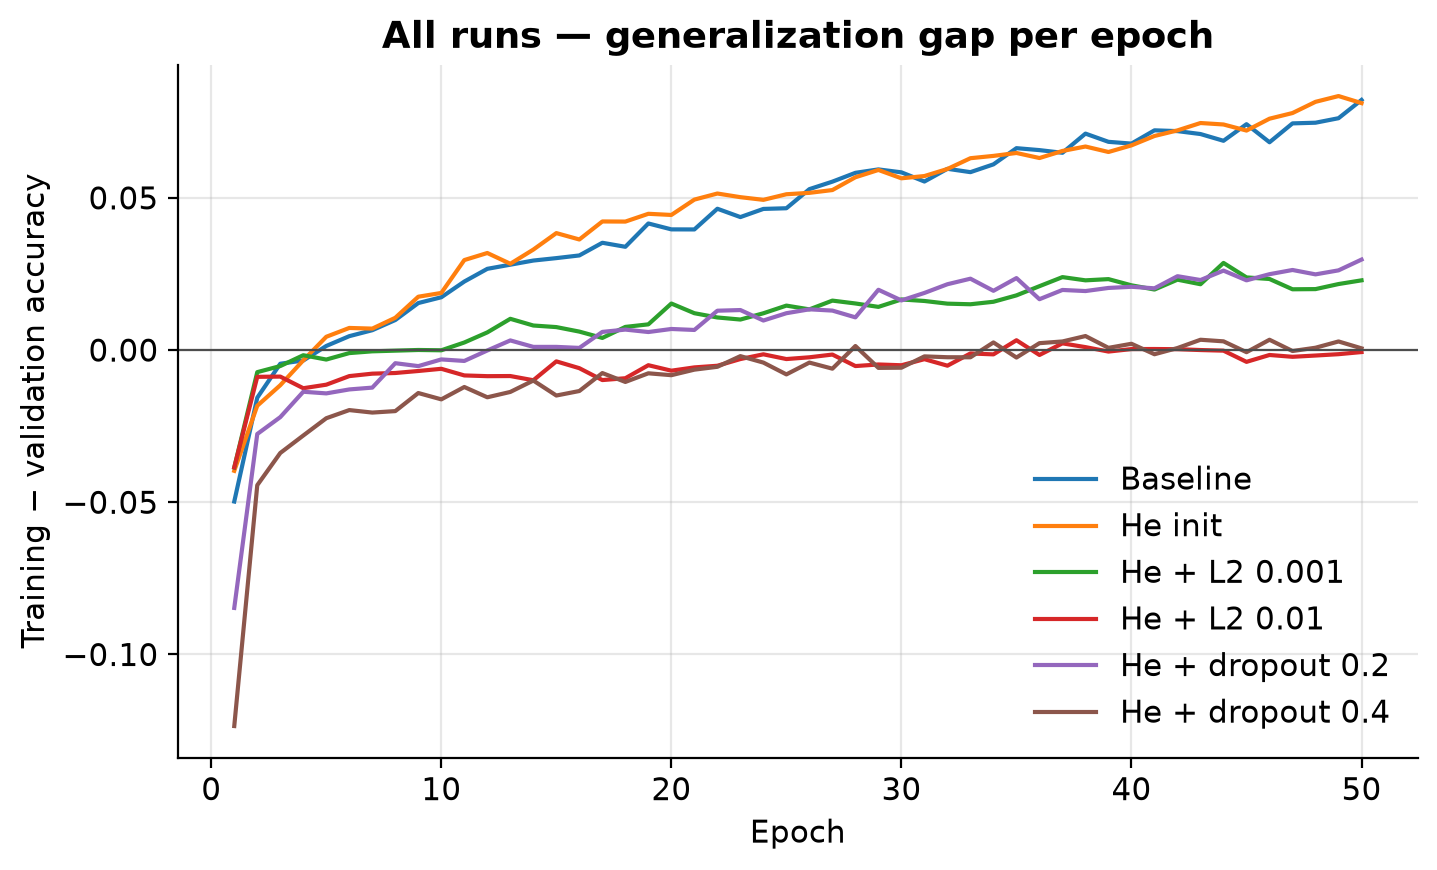

In [70]:
plot_gap(all_runs, "All runs — generalization gap per epoch")

### Early stopping

Every run trained for all 50 epochs and kept the weights from its best epoch. The table below uses the recorded histories to measure two things: how much validation accuracy restoring the best epoch kept over the epoch-50 weights, and which epoch a rule based on validation *loss* would have picked, with its validation accuracy.

In [71]:
def early_stopping_effect(run: Run) -> dict[str, float]:
    """What restoring the best-accuracy epoch kept, and what a lowest-validation-loss rule would pick."""
    history = run.history
    loss_epoch = int(history["val_loss"].idxmin())
    kept = history.loc[run.best_epoch, "val_accuracy"]
    last = history["val_accuracy"].iloc[-1]
    return {
        "Best epoch (val acc)": run.best_epoch,
        "Val acc, best epoch": kept,
        f"Val acc, epoch {EPOCHS}": last,
        "Kept by restoring": kept - last,
        "Epoch of lowest val loss": loss_epoch,
        "Val acc, lowest-val-loss epoch": history.loc[loss_epoch, "val_accuracy"],
    }


pd.DataFrame.from_dict({run.config.name: early_stopping_effect(run) for run in all_runs}, orient="index")

,Best epoch (val acc),"Val acc, best epoch","Val acc, epoch 50",Kept by restoring,Epoch of lowest val loss,"Val acc, lowest-val-loss epoch"
Baseline,21,0.8987,0.8852,0.0135,8,0.8926
He init,31,0.8968,0.8881,0.0087,8,0.8917
He + L2 0.001,48,0.8920,0.8893,0.0027,33,0.8907
He + L2 0.01,45,0.8667,0.8646,0.0021,45,0.8667
He + dropout 0.2,41,0.9031,0.8982,0.0049,28,0.9003
He + dropout 0.4,50,0.8977,0.8977,0.0000,45,0.8958


**Reading the table.** Restoring the best epoch mattered most where overfitting was strongest. Training to the end would have cost the unregularized runs 1.35 points (baseline) and 0.87 points (He init). The regularized runs lose little by training on: 0.27 and 0.21 points for the two L2 strengths, 0.49 for dropout 0.2, and nothing for dropout 0.4, whose best epoch is the last. Early stopping and the two regularizers are therefore partly substitutes: once L2 or dropout keeps the network from overfitting, the stopping point matters less.

The two stopping criteria disagree. In both unregularized runs, validation loss is lowest at epoch 8, 13 and 23 epochs before validation accuracy peaks. The epoch-8 weights score 0.8926 and 0.8917, 0.61 and 0.51 points below the peaks. A likely mechanism, not measured here: the network keeps correcting some wrong predictions while growing more confident on those it still gets wrong, which raises accuracy and cross-entropy together. A loss rule therefore stops sooner and keeps lower cross-entropy; an accuracy rule, the brief's metric, stops later and keeps higher top-1 accuracy. For dropout 0.2 the two rules nearly agree (epoch 28 at 0.9003 against epoch 41 at 0.9031). On these flat curves, the choice of rule changes the retained accuracy by less than one point.

**Table 1: summary comparison.**

In [72]:
KEY_OBSERVATIONS = {
    "Baseline (no techniques)": (
        "Learns fast, then overfits: val loss bottoms at epoch 8 and climbs to epoch 50; "
        "val acc plateaus near 0.90 while the gap widens"
    ),
    "He initialization": (
        "Activation scale preserved as predicted; one epoch faster to 0.88, "
        "but best val acc a tie with Glorot and the same per-epoch gap curve"
    ),
    "Best L2 model": (
        "Gap cut by about two thirds and weights shrunk sixfold; lower training fit, "
        "val acc within noise of He init"
    ),
    "Best dropout model": (
        "Highest val acc and lowest val CE; keeps full-network training fit; "
        "Keras train acc understated by dropout"
    ),
    "Final selected model": (
        "Chosen on validation only; test accuracy 1.58 points below validation, "
        "mostly a validation/test difference (see Step 6)"
    ),
}
roles = {
    "Baseline (no techniques)": baseline,
    "He initialization": he,
    "Best L2 model": best_l2,
    "Best dropout model": best_dropout,
    "Final selected model": final,
}
table_1 = pd.DataFrame.from_dict(
    {
        (role if role in ("Baseline (no techniques)", "He initialization") else f"{role} ({run.config.name})"): {
            "Training accuracy": run.history.loc[run.best_epoch, "accuracy"],
            "Train acc, dropout off": inference_metrics(run.model, data.train)[1],
            "Validation accuracy": run.history.loc[run.best_epoch, "val_accuracy"],
            "Best epoch": run.best_epoch,
            "Key observation": KEY_OBSERVATIONS[role],
        }
        for role, run in roles.items()
    },
    orient="index",
).rename_axis("Model")
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(table_1)

,Training accuracy,"Train acc, dropout off",Validation accuracy,Best epoch,Key observation
Model,,,,,
Baseline (no techniques),0.9383,0.9321,0.8987,21,"Learns fast, then overfits: val loss bottoms at epoch 8 and climbs to epoch 50; val acc plateaus near 0.90 while the gap widens"
He initialization,0.9540,0.9389,0.8968,31,"Activation scale preserved as predicted; one epoch faster to 0.88, but best val acc a tie with Glorot and the same per-epoch gap curve"
Best L2 model (He + L2 0.001),0.9120,0.9098,0.8920,48,"Gap cut by about two thirds and weights shrunk sixfold; lower training fit, val acc within noise of He init"
Best dropout model (He + dropout 0.2),0.9234,0.9351,0.9031,41,Highest val acc and lowest val CE; keeps full-network training fit; Keras train acc understated by dropout
Final selected model (He + dropout 0.2),0.9234,0.9351,0.9031,41,"Chosen on validation only; test accuracy 1.58 points below validation, mostly a validation/test difference (see Step 6)"


### Overall pattern

Initialization changed how training started; regularization changed how it ended. He initialization preserved activation scale as predicted and reached 0.88 validation accuracy one epoch sooner. Little else changed. Best validation accuracy tied (0.8968 against 0.8987), and validation loss was lowest at epoch 8 in both runs. The per-epoch gap curves lie on top of each other (epoch-50 gaps 0.0811 and 0.0822).

Both regularizers narrowed the best-epoch gap: L2 at λ = 0.001 from 0.0572 to 0.0200, and dropout 0.2 to 0.0203. Both also stopped validation loss from climbing after its minimum. They worked differently. L2 shrank the weights (hidden-kernel norm 56.2936 to 9.0284) and gave up training fit (full-network training accuracy 0.9389 to 0.9098), with no validation gain. Dropout left the weights large (59.1528), kept the training fit nearly intact (0.9351), and raised validation accuracy to 0.9031. Restoring the best epoch mattered most without regularization: it kept 1.35 and 0.87 points of validation accuracy in the unregularized runs, against at most 0.49 in the regularized ones. The strong settings (λ = 0.01, dropout 0.4) show the other side of the trade-off: gaps near zero, but lower training *and* validation accuracy than the milder settings.

**Dropout had the most meaningful effect on generalization.** It is the only technique that raised validation accuracy by more than Step 6's half-point convention: 0.63 points over He init, a suggestive margin on one seed (see Step 6). It also reached the lowest validation loss of any run (0.2886 at epoch 28, against 0.3122 for He init at epoch 8). Its clearest effect is on the shape of training: validation loss stays near its minimum instead of climbing (0.3080 at epoch 50, against 0.5240 for He init).

## Final analysis and reflection

### Question 1

*How did weight initialization and regularization affect training behavior, convergence, and stability, and the relationship between training and validation performance?*

Weight initialization acted on the start of training and little else. He-normal initialization sets each hidden kernel's variance to 2 / fan-in, and it preserved activation scale as predicted. Its RMS ratios were 1.0266 and 0.9869 for the two hidden layers, against 0.9255 and 0.6429 under the Keras default, Glorot-uniform.

That difference barely reached training. Both models started at chance-level validation loss (2.3598 and 2.3802), and He init reached 0.88 validation accuracy one epoch sooner (epoch 3 against 4). From epoch 4 on, the two validation curves stayed within about a point and crossed repeatedly. Stability was similar. He init had more epochs with rising training loss (6 against 2) and a slightly larger spread in epoch-to-epoch validation changes (0.0047 against 0.0041); neither run diverged or oscillated widely.

Initialization also left the relationship between training and validation unchanged. Both runs reached their lowest validation loss at epoch 8 (0.3032 and 0.3122) and then overfit: by epoch 50, validation loss had climbed to 0.5467 and 0.5240 and the gap had widened to 0.0822 and 0.0811. Their best validation accuracies, 0.8987 and 0.8968, tie within one standard error (0.0030). The likely reason is that, with only two hidden layers, Glorot's activation shrinkage has little room to compound, and Adam rescales each parameter's step. Depth and optimizer were fixed by design, so the evidence does not isolate this explanation.

Regularization acted on the end of training. Without it, training accuracy kept climbing after validation accuracy plateaued near 0.90, so the gap kept widening through epoch 50.

L2 at λ = 0.001 shrank the hidden-kernel norm from 56.2936 to 9.0284. It cut the gap from 0.0572 to 0.0200 at the best epoch and from 0.0811 to 0.0229 at epoch 50. Validation loss stayed nearly flat after its minimum (0.3888 at epoch 33, 0.3979 at epoch 50, penalty included). The price was training fit: full-network training accuracy fell from 0.9389 to 0.9098, with no validation gain (0.8920 against 0.8968). At λ = 0.01 the penalty dominated. The norm fell to 2.9633, and training and validation accuracy dropped together to 0.8628 and 0.8667; that gap of −0.0039 signals underfitting, not good generalization.

Dropout 0.2 worked through a different mechanism. Each mini-batch trains a different thinned sub-network, which discourages co-adapted units, and the weights grew rather than shrank (norm 59.1528). It cut the best-epoch gap to 0.0203 while keeping full-network training accuracy at 0.9351 and raising validation accuracy to 0.9031. Keras's training accuracy, measured on the thinned networks, understates this fit. At rate 0.4 it was level with validation at the best epoch (0.8983 against 0.8977), although the full network scored 0.9230 on the training images.

Both regularizers flattened the late validation-loss curve and delayed its minimum. The minimum moved from epoch 8 in both unregularized runs to epochs 33 and 45 with L2 and 28 and 45 with dropout. That delay is consistent with slowing the network's fit to training-specific detail. Early stopping, here restoring the best epoch, acted as a third regularizer whose value depended on the other two. It kept 1.35 points of validation accuracy for the baseline and 0.87 for He init, but at most 0.49 for the regularized runs. A validation-loss rule would have stopped the unregularized runs at epoch 8, trading 0.61 and 0.51 points of accuracy for lower cross-entropy. That trade shows that loss and accuracy measure different aspects of generalization.

These results rest on one seed per configuration and a 50-epoch budget. Small margins may not replicate, and the slow-converging runs (λ = 0.001, dropout 0.4) might gain with more epochs.

### Question 2

*Which model provided the best balance between fitting the training data and generalizing to validation and test data? Why can a model with lower training accuracy still be the better model?*

He initialization with dropout 0.2 gave the best balance. It had the highest validation accuracy of the six runs, 0.9031 at epoch 41: 0.63 points above He init without regularization and 1.11 points above the better L2 model. It also had the lowest validation cross-entropy at its best epoch (0.2948) and the lowest validation loss over training (0.2886). Both its predicted probabilities and its top choices therefore fit the validation labels best. It did this while fitting the training data almost as fully as the unregularized network (full-network training accuracy 0.9351 against 0.9389), with a full-network gap of 0.0320 against 0.0421. Two limitations apply. Each configuration ran with one seed, and each best validation accuracy is itself a maximum over 50 epochs. With a margin over He init of about 1.5 standard errors of a difference between two runs (Step 6), the ranking is suggestive rather than definitive.

Evaluated once on the untouched test set, the model scored 0.8873 accuracy and 0.3445 cross-entropy. Test accuracy is 1.58 points below validation, about 3.6 standard errors of the difference. Picking the best epoch explains at most about 0.5 points, since the same run scores 0.8982 on validation at epoch 50. Most of the drop, about 1.1 points, suggests a systematic difference between the validation images, drawn from Fashion-MNIST's training file, and the separately provided test set.

A model with lower training accuracy can still be the better model because training accuracy measures fit to images the model has already seen, noise included. The goal is accuracy on unseen images. Once validation stops improving, extra training accuracy comes from memorizing training-specific detail that does not transfer. Here that detail made the unregularized models *worse* on held-out data: He init's validation loss rose from 0.3122 to 0.5240 while its training accuracy kept climbing.

The experiments show this trade directly. He init had the highest Keras training accuracy at its best epoch (0.9540) but lower validation accuracy than dropout 0.2 (0.8968 against 0.9031), whose Keras training accuracy was 0.9234. Part of that lower figure is a measurement effect: with dropout off, the same weights score 0.9351 on the training images. The rest is genuine: regularization gives up some training fit to reduce variance, and the right amount is the one that maximizes validation performance. Lower training accuracy is a virtue only while validation holds or improves. L2 at λ = 0.01 had the lowest training accuracy (0.8628) and also the lowest validation accuracy (0.8667): it was underfitting.

### References

The data are Xiao et al.'s (2017) Fashion-MNIST, loaded through Keras (Chollet et al., 2015), and the validation split uses scikit-learn (Pedregosa et al., 2011). Models are built and trained with Keras on TensorFlow (Abadi et al., 2015), with the Adam optimizer (Kingma & Ba, 2015) and the Keras default Glorot-uniform initialization (Glorot & Bengio, 2010). He initialization follows He et al. (2015), dropout Srivastava et al. (2014), and the note on L2 under Adam Loshchilov and Hutter (2019); Goodfellow et al. (2016) is the general reference for regularization and early stopping. Arrays, tables, and figures use NumPy (Harris et al., 2020), pandas (McKinney, 2010), and Matplotlib (Hunter, 2007).

Abadi, M., Agarwal, A., Barham, P., Brevdo, E., Chen, Z., Citro, C., Corrado, G. S., Davis, A., Dean, J., Devin, M., Ghemawat, S., Goodfellow, I., Harp, A., Irving, G., Isard, M., Jia, Y., Jozefowicz, R., Kaiser, L., Kudlur, M., . . . Zheng, X. (2015). *TensorFlow: Large-scale machine learning on heterogeneous systems* [Computer software]. <https://www.tensorflow.org/>

Chollet, F., & others. (2015). *Keras* [Computer software]. <https://keras.io>

Glorot, X., & Bengio, Y. (2010). Understanding the difficulty of training deep feedforward neural networks. In Y. W. Teh & M. Titterington (Eds.), *Proceedings of the Thirteenth International Conference on Artificial Intelligence and Statistics* (pp. 249–256). PMLR. <https://proceedings.mlr.press/v9/glorot10a.html>

Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press. <https://www.deeplearningbook.org>

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., Fernández del Río, J., Wiebe, M., Peterson, P., . . . Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, *585*(7825), 357–362. <https://doi.org/10.1038/s41586-020-2649-2>

He, K., Zhang, X., Ren, S., & Sun, J. (2015). Delving deep into rectifiers: Surpassing human-level performance on ImageNet classification. In *Proceedings of the IEEE International Conference on Computer Vision* (pp. 1026–1034). <https://doi.org/10.1109/ICCV.2015.123>

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, *9*(3), 90–95. <https://doi.org/10.1109/MCSE.2007.55>

Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. In *3rd International Conference on Learning Representations (ICLR 2015)*. <https://arxiv.org/abs/1412.6980>

Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. In *International Conference on Learning Representations*. <https://openreview.net/forum?id=Bkg6RiCqY7>

McKinney, W. (2010). Data structures for statistical computing in Python. In S. van der Walt & J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 56–61). <https://doi.org/10.25080/Majora-92bf1922-00a>

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, *12*, 2825–2830. <https://jmlr.org/papers/v12/pedregosa11a.html>

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research*, *15*(56), 1929–1958. <https://jmlr.org/papers/v15/srivastava14a.html>

Xiao, H., Rasul, K., & Vollgraf, R. (2017). *Fashion-MNIST: A novel image dataset for benchmarking machine learning algorithms* (arXiv:1708.07747). arXiv. <https://doi.org/10.48550/arXiv.1708.07747>